# Motor Parameter Identification (Week 5, Assignment 1)

- **Full name:** Adhambek Yashnarbekov
- **Student ID:** 240062
- **Module:** CSC 413 Robotics
- **Professor:** Aleksandr Kapitonov

In this assignment I identify the parameters of the two drive motors of my TRIK robot from my own measurements:

- M3: right wheel (encoder E3)
- M4: left wheel (encoder E4)

I recorded step responses in both directions (M4 twice), an extra step series with 1 % steps for the dead zone, a square wave and a chirp. I fit the first-order model from the course notebook `Motor_identification.ipynb`. Then I compare the identified model with the real motor on the square wave and the chirp, and I analyse the artifacts that I found in the data.

**Structure**
1. Motor model
2. Test signals
3. Data collection programs in TRIK Studio
4. Data processing: 4.1 loading, 4.2 step responses, 4.3 speed and $T_m$ from PWM, 4.4 complex signals
5. Artifact analysis
6. Report: estimated values, list of plots, analysis

**How to run:** the notebook reads the raw files from the folder `motor_data/`. In Google Colab, run the first code cell and upload the `.txt` files from `motor_data/` when it asks. Then use *Runtime → Run all*.

### Setup
Libraries, upload of the raw files (only in Colab) and common settings. `U_BAT` = 11.2 V is the battery voltage that I measured. I use it to convert PWM to volts (see Section 3).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint
from IPython.display import display

DATA = 'motor_data'                        # folder with the raw files from the robot
os.makedirs(DATA, exist_ok=True)
try:                                       # Google Colab only: upload the raw .txt files once
    from google.colab import files
    if not any(name.endswith('.txt') for name in os.listdir(DATA)):
        for name in files.upload():        # select all .txt files from my motor_data/ folder
            os.replace(name, os.path.join(DATA, name))
except ImportError:
    pass                                   # local Jupyter: the files are already in motor_data/

U_BEFORE, U_AFTER = 11.2, 11.2     # V, battery voltage I noted before and after the series (battery.txt)
U_BAT = (U_BEFORE + U_AFTER) / 2   # V, used to convert PWM to volts: U = PWM/100 * U_BAT
WHEEL = {'M3': 'right wheel', 'M4': 'left wheel'}
DIR_COLOR = {'fwd': 'tab:blue', 'bwd': 'tab:red'}     # colour = direction of rotation
MARKER = {'M3': 'o', 'M4': 's'}                       # marker = motor
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})
print(sorted(os.listdir(DATA)))

['chirp_M3.txt', 'chirp_M4.txt', 'deadzone_M3.txt', 'deadzone_M4.txt', 'square_M3.txt', 'square_M4.txt', 'steps_M3.txt', 'steps_M4.txt', 'steps_M4_repeat.txt']


## 1. Motor model

If I neglect the armature inductance, a lightly loaded DC motor is a first-order system in angular velocity (equation 5 of the course notebook):

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega$$

### 1.1 The parameters in my own words

| Symbol | Meaning (my words) | Unit |
|---|---|---|
| $U$ | The voltage on the motor. TRIK does not set volts, it sets PWM in %, so I compute $U = \frac{\text{PWM}}{100}\,U_{battery}$. | V |
| $\theta$ | The angle of the shaft: how far the wheel has turned. The encoder gives degrees, I convert them to radians. | rad |
| $\omega$ | The angular velocity: how fast the angle changes. | rad/s |
| $\omega_{ss}$ | The steady-state speed: the constant speed that the motor reaches when the voltage stays the same for a long time. In the model $\omega_{ss} = U/k_e$. | rad/s |
| $T_m$ | The electromechanical time constant. It shows how fast the motor speeds up. After $t = T_m$ the speed is 63 % of $\omega_{ss}$, after $3T_m$ it is 95 %. It depends on the inertia $J$ and the resistance $R$: $T_m = JR/(k_m k_e)$. | s |
| $k_e$ | The back-EMF constant: how many volts I need for each 1 rad/s of speed. A big $k_e$ means a slow motor for the same voltage. | V·s/rad |

### 1.2 How θ(t) follows from the equation for a step input

At $t = 0$ the motor is at rest ($\omega(0) = 0$, $\theta(0) = 0$) and I switch on a constant voltage $U$.

**Step 1: steady state.** When the speed stops changing, $d\omega/dt = 0$. So $0 = \frac{U}{T_m k_e} - \frac{\omega_{ss}}{T_m}$, and $\omega_{ss} = U/k_e$. With this the equation becomes

$$T_m\frac{d\omega}{dt} = \omega_{ss} - \omega .$$

**Step 2: speed.** I separate the variables and integrate from 0 to $t$:

$$\int_0^{\omega}\frac{d\omega}{\omega_{ss}-\omega} = \int_0^{t}\frac{dt}{T_m}
\;\;\Rightarrow\;\; -\ln\frac{\omega_{ss}-\omega}{\omega_{ss}} = \frac{t}{T_m}
\;\;\Rightarrow\;\; \omega(t) = \omega_{ss}\left(1 - e^{-t/T_m}\right)$$

At $t = T_m$ the speed is $\omega_{ss}(1 - e^{-1}) \approx 0.63\,\omega_{ss}$. This is why $T_m$ is "the time to reach 63 %".

**Step 3: angle.** I integrate the speed:

$$\theta(t) = \int_0^{t}\omega_{ss}\left(1 - e^{-\tau/T_m}\right)d\tau = \omega_{ss}\Big[\tau + T_m e^{-\tau/T_m}\Big]_0^{t} = \omega_{ss}\left(t + T_m e^{-t/T_m} - T_m\right)$$

$$\boxed{\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right)}$$

Check: $\theta(0) = \omega_{ss}(0 - T_m + T_m) = 0$. For large $t$ the exponent goes to zero and $\theta \approx \omega_{ss}(t - T_m)$. This is a straight line with slope $\omega_{ss}$, shifted by $T_m$. So the slope of the measured angle gives $\omega_{ss}$, and the bend at the start gives $T_m$. This is the function I fit with `curve_fit`.

### 1.3 Assumptions of the model
1. No inductance ($L = 0$): the current changes immediately when the voltage changes.
2. Linear viscous friction: the friction torque is proportional to the speed (no dry friction, so no dead zone).
3. Constant load: inertia and friction do not change during a run. My wheels were lifted, so the load is only the wheel itself.
4. Constant battery voltage within a run: one value of $U_{battery}$ for the whole run.

The model also says that $T_m$ and $k_e$ are constants, the same for every PWM and for both directions. I test every assumption with my data in Section 5.12.

## 2. Test signals

| Signal | My settings | Why I used it |
|---|---|---|
| Step series | −100 % … +100 % in 10 % steps (0 % skipped). Every level: 2 s motor on + 1 s coasting. 3 s with the motor off at the start. Both motors, M4 twice (repeatability). | $\omega_{ss}$ and $T_m$ at every level, both directions, asymmetry, saturation, coasting |
| Fine low-PWM steps ("dead-zone run") | −9 % … +9 % in 1 % steps, same timing | 10 % steps are too coarse to find the dead zone, so I added this extra series |
| Square wave | $A = 60$ %, $P = 1$ s, $T = 8$ s | many accelerations and reversals in both directions, backlash, $T_m$ in both directions in one run |
| Chirp | $A = 60$ %, $f_0 = 0.2$ Hz → $f_1 = 5$ Hz in $T = 8$ s | frequency response (the speed amplitude falls when the frequency grows), direct check of $T_m$ |

The formulas in my TRIK program ($t$ in s, $\text{frac}(x) = x - \text{floor}(x)$):
- square: $u = A\cdot\text{sgn}(0.5 - \text{frac}(t/P))$. This is $+A$ in the first half of every period and $-A$ in the second half.
- chirp: $u = A\sin\left(2\pi\left(f_0 t + \frac{(f_1-f_0)\,t^2}{2T}\right)\right)$.

My Program B also has the sawtooth and the triangle (`kind = 2, 3`), but I recorded the square (`kind = 1`) and the chirp (`kind = 4`).

**Design rules check** (with $T_m \approx 0.17$–$0.19$ s, the mean of my steps):
- Square: $P = 1$ s is about 5–6 $T_m$. Every half period (0.5 s) is about 3 $T_m$, so the speed gets close to its final value before each reversal (in theory about 90 %, because it starts from $-\omega$). OK.
- Chirp: $1/(2\pi T_m) \approx 0.83$–$0.95$ Hz. The chirp starts at 0.2 Hz (about 4–5 times lower) and ends at 5 Hz (about 5–6 times higher). OK.
- Both signals cross zero, so both directions and the dead zone are in the same run. OK.
- The amplitude is 60 % ≤ 80 %, so the model is not tested only in saturation. OK.

## 3. Data collection programs in TRIK Studio

I built both programs from blocks in TRIK Studio visual programming. There is no JavaScript or Python text code on the robot.

**Program A, step series** (`motor_steps.qrs`):
1. `[Remove File]` → `[Clear Encoder]` (E3 or E4) → `[Function] level = -100`
2. Zero-drift check: `[Function] t0 = time()`, then `[Loop] while time() - t0 < 3000`: `[Function] theta = encoder; t = time(); st = theta .. "," .. t .. ",0\n"` → `[Write To File] st` → `[Timer] 5 ms`
3. `[Loop] while level <= 100`: `[Condition] level != 0` → `t0 = time()`, `[Motor] power = level`, log θ, t, level for 2 s. Then `[Motor] power = 0` and log θ, t, 0 until 3 s (coasting). Then `level = level + 10`.
4. `[Motor stop]` (float).

For the dead-zone run I used the same program, but `level` goes from −9 to +9 with step 1.

**Program B, complex signal** (`motor_signal.qrs`): `[Function] A = 60; P = 1000; T = 8000; kind = 1 (square) or 4 (chirp); f0 = 0.2; f1 = 5`. In every loop cycle: `tau = time() - t0`, `fr = tau/P - floor(tau/P)`, `u` from the formula, `u = floor(u + 0.5)` (rounding), `[Motor] power = u`, log θ, t, u, `[Timer] 5 ms`. After T: `power = 0`, 1 s of logged coasting, `[Motor stop]`.

**Setup and notes**
- The robot was lifted, so the wheels turned freely in the air (no load). I did not do the optional run on the floor.
- M3 + E3 = right wheel, M4 + E4 = left wheel. Between the motors I changed only the motor port, the encoder port and the file name.
- I ran Program A twice on M4 (`steps_M4.txt` and `steps_M4_repeat.txt`) to check repeatability.
- Battery voltage: I noted the battery voltage before and after every series. It was 11.2 V before and 11.2 V after each time, so it did not change during the whole lab. I use $U_{battery} = 11.2$ V for all runs. My readings are in `battery.txt`.
- The timer is 5 ms, but the real sampling interval is about 20 ms in Program A and about 30 ms in Program B. Writing to the file takes time, and Program B does more work in every cycle (Section 5.7).
- Every line of a file is `angle_deg,time_ms,PWM`. The notebook uses the raw files without any changes.

## 4. Data processing

### 4.1 Loading and SI conversion
My files have three columns: angle (deg), time (ms) and PWM (%). This order is different from the course notebook (time, angle), so I changed the loading line. I convert the angle to radians and the time to seconds. Later, in every segment I subtract the first time and the first angle, so that each segment starts at $t = 0$, $\theta = 0$.

In [2]:
def load(name):
    """Read one raw file. Columns: angle [deg], time [ms], PWM [%]."""
    angle_deg, time_ms, pwm = np.loadtxt(os.path.join(DATA, name + '.txt'), delimiter=',', unpack=True)
    return np.deg2rad(angle_deg), time_ms / 1000, pwm          # SI units: rad, s (PWM stays in %)

FILES = ['steps_M3', 'steps_M4', 'steps_M4_repeat', 'deadzone_M3', 'deadzone_M4',
         'square_M3', 'square_M4', 'chirp_M3', 'chirp_M4']
raw = {name: load(name) for name in FILES}

rows = []
for name, (theta, t, pwm) in raw.items():
    dt = 1000 * np.diff(t)                                      # ms
    rows.append([name, len(t), t[-1] - t[0], pwm.min(), pwm.max(), 1000 * t[0],
                 dt.mean(), dt.min(), dt.max()])
summary = pd.DataFrame(rows, columns=['file', 'samples', 'duration, s', 'PWM min, %', 'PWM max, %',
                                      'first time(), ms', 'mean dt, ms', 'min dt, ms', 'max dt, ms'])
display(summary.round(1))

,file,samples,"duration, s","PWM min, %","PWM max, %","first time(), ms","mean dt, ms","min dt, ms","max dt, ms"
0,steps_M3,3081,63.2,-100.0,100.0,43.0,20.5,14.0,54.0
1,steps_M4,3088,63.2,-100.0,100.0,38.0,20.5,13.0,63.0
2,steps_M4_repeat,3045,63.2,-100.0,100.0,36.0,20.8,13.0,47.0
3,deadzone_M3,2753,57.2,-9.0,9.0,43.0,20.8,13.0,52.0
4,deadzone_M4,2741,57.2,-9.0,9.0,27.0,20.9,13.0,50.0
5,square_M3,306,9.0,-60.0,60.0,71.0,29.4,14.0,50.0
6,square_M4,301,9.0,-60.0,60.0,67.0,29.9,15.0,51.0
7,chirp_M3,308,9.0,-60.0,60.0,65.0,29.3,15.0,50.0
8,chirp_M4,309,9.0,-60.0,60.0,70.0,29.2,16.0,51.0


The first `time()` value is not 0. It is 27–43 ms in Program A and 65–71 ms in Program B, because `time()` starts with the program and the first sample comes after `Remove File` and `Clear Encoder`. The mean interval between samples is about 20.5 ms in the step files and about 29.5 ms in the square and chirp files.

### 4.2 Step responses
I split every step file into segments by the PWM column: a new segment starts every time the PWM value changes. For every nonzero level I take the 2 s with the motor on, subtract the first time and the first angle, and fit the course model with `optimize.curve_fit`. I also keep the coasting part after every level (I use it in Section 5.5).

Two small changes to the course code. First, as first guess I use the mean speed of the segment instead of the fixed `p0 = [8, 0.1]`, because the speed is negative for the backward levels. Second, I limit $T_m$ to 0.001–5 s, so that it cannot become negative.

In [3]:
def split_levels(theta, t, pwm):
    """Split a step file by the PWM column. For every nonzero level return the motor-on part
    (time and angle start from 0) and the coasting part after it (PWM = 0)."""
    edges = np.flatnonzero(np.diff(pwm) != 0) + 1          # rows where the PWM value changes
    bounds = np.r_[0, edges, len(pwm)]
    segs = []
    for k in range(len(bounds) - 1):
        a, b = bounds[k], bounds[k + 1]                    # rows a .. b-1 have the same PWM
        if pwm[a] == 0:
            continue                                       # zero-drift block or coasting part
        c = bounds[k + 2] if k + 2 < len(bounds) else b    # end of the coasting part after this level
        segs.append({'level': pwm[a],
                     't': t[a:b] - t[a], 'theta': theta[a:b] - theta[a],                         # motor on
                     't_off': t[b - 1:c] - t[b - 1], 'theta_off': theta[b - 1:c] - theta[b - 1]})  # coasting
    return segs

def model(t, speed, T_m):                                  # theta(t) for a step input (Section 1)
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)

def fit_step(t, theta):
    p0 = [theta[-1] / t[-1], 0.1]                          # first guess: mean speed, 0.1 s
    popt, pcov = optimize.curve_fit(model, t, theta, p0=p0,
                                    bounds=([-np.inf, 1e-3], [np.inf, 5]))   # T_m between 0.001 and 5 s
    return popt, np.sqrt(np.diag(pcov))                    # (w_ss, T_m) and their standard errors

segs, tab = {}, {}
for name in ('steps_M3', 'steps_M4', 'steps_M4_repeat'):
    segs[name] = split_levels(*raw[name])
    rows = []
    for s in segs[name]:
        (w, Tm), (w_err, Tm_err) = fit_step(s['t'], s['theta'])
        s['w_ss'], s['T_m'] = w, Tm
        rows.append([s['level'], s['level'] / 100 * U_BAT, w, w_err, Tm, Tm_err, s['theta_off'][-1]])
    tab[name] = pd.DataFrame(rows, columns=['PWM', 'U', 'w_ss', 'w_err', 'T_m', 'T_m_err', 'coast'])

for name, tb in tab.items():
    for _, r in tb[tb.T_m < 0.002].iterrows():                # T_m stuck at the lower limit
        print(f'Note: {name}, {r.PWM:+.0f} %: T_m = {r.T_m:.3f} s is the lower limit, so this fit failed.')

for name in ('steps_M3', 'steps_M4'):
    m = name[-2:]
    print(f'{m} ({WHEEL[m]}), run 1: w_ss and T_m with standard errors from pcov')
    show = tab[name].rename(columns={'PWM': 'PWM, %', 'U': 'U, V', 'w_ss': 'w_ss, rad/s', 'w_err': 's.e. w_ss',
                                     'T_m': 'T_m, s', 'T_m_err': 's.e. T_m', 'coast': 'coasting angle, rad'})
    display(show.round({'U, V': 1, 'w_ss, rad/s': 2, 's.e. w_ss': 3, 'T_m, s': 3, 's.e. T_m': 4,
                        'coasting angle, rad': 2}))

Note: steps_M4_repeat, +10 %: T_m = 0.001 s is the lower limit, so this fit failed.
M3 (right wheel), run 1: w_ss and T_m with standard errors from pcov


,"PWM, %","U, V","w_ss, rad/s",s.e. w_ss,"T_m, s",s.e. T_m,"coasting angle, rad"
0,-100.0,-11.2,-14.40,0.003,0.033,0.0003,-5.46
1,-90.0,-10.1,-13.47,0.004,0.073,0.0004,-3.58
2,-80.0,-9.0,-12.58,0.004,0.114,0.0004,-5.22
3,-70.0,-7.8,-11.59,0.007,0.145,0.0007,-4.64
4,-60.0,-6.7,-10.61,0.017,0.107,0.0018,-4.00
5,-50.0,-5.6,-9.85,0.010,0.204,0.0011,-3.51
6,-40.0,-4.5,-9.06,0.021,0.109,0.0026,-3.05
7,-30.0,-3.4,-7.53,0.005,0.293,0.0008,-2.08
8,-20.0,-2.2,-6.26,0.006,0.332,0.0011,-1.59
9,-10.0,-1.1,-4.67,0.006,0.453,0.0016,-0.86


M4 (left wheel), run 1: w_ss and T_m with standard errors from pcov


,"PWM, %","U, V","w_ss, rad/s",s.e. w_ss,"T_m, s",s.e. T_m,"coasting angle, rad"
0,-100.0,-11.2,-13.92,0.004,0.040,0.0003,-4.10
1,-90.0,-10.1,-12.56,0.004,0.064,0.0004,-3.94
2,-80.0,-9.0,-11.47,0.004,0.102,0.0004,-3.53
3,-70.0,-7.8,-10.27,0.006,0.134,0.0006,-2.84
4,-60.0,-6.7,-9.20,0.005,0.154,0.0007,-2.43
5,-50.0,-5.6,-8.27,0.007,0.176,0.0010,-2.06
6,-40.0,-4.5,-7.48,0.005,0.186,0.0007,-1.66
7,-30.0,-3.4,-6.14,0.010,0.237,0.0018,-1.33
8,-20.0,-2.2,-4.82,0.011,0.244,0.0026,-0.80
9,-10.0,-1.1,-3.36,0.004,0.354,0.0015,-0.42


The standard errors from `pcov` are very small (at most about 0.02 rad/s for $\omega_{ss}$ and 0.003 s for $T_m$). They only show how well one curve fits one record. The real uncertainty is larger. When I repeat the M4 series, $\omega_{ss}$ changes by only 1.7 % on average, but $T_m$ changes by 12 % (median) and by up to about 60 % at single levels (Section 5.8). One fit failed: in the repeated M4 run at +10 % the fit gives $T_m$ = 0.001 s, which is just the lower limit (the reason is in Section 5.6). I use the repeated run only to check repeatability, not for the parameters.

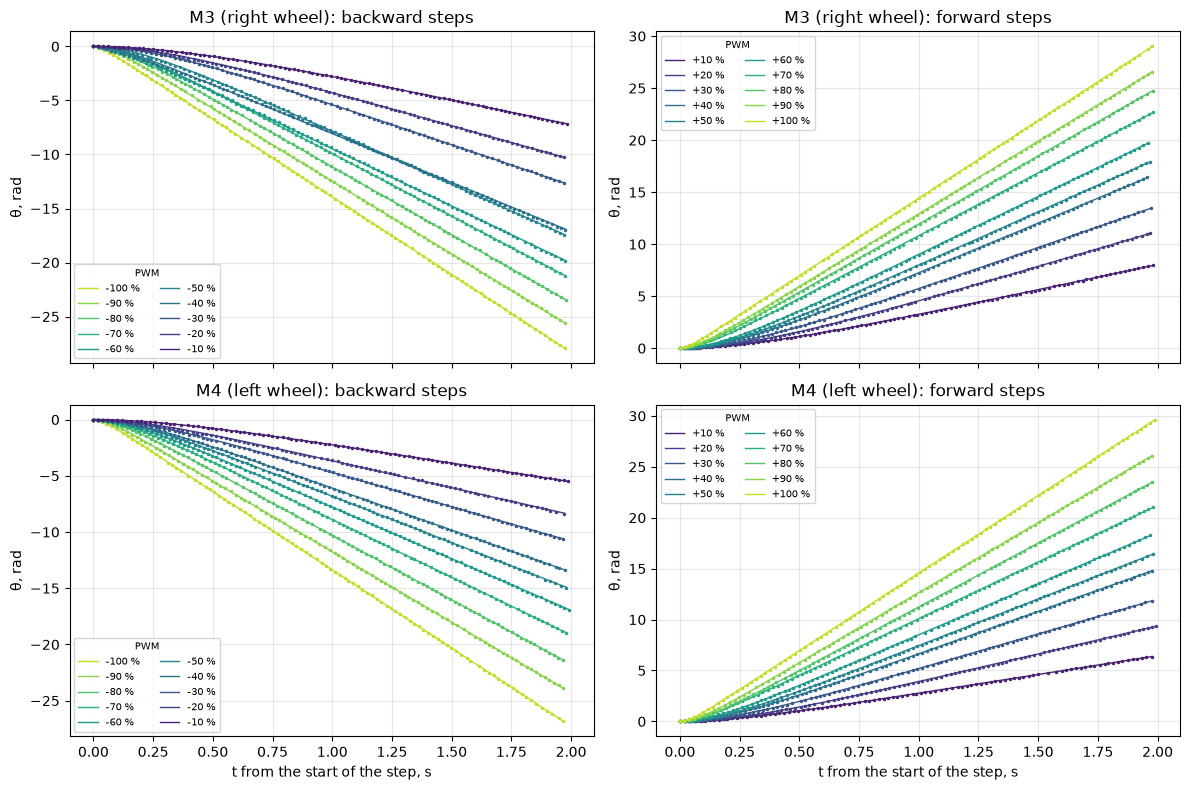

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
cmap = plt.get_cmap('viridis')
for row, m in enumerate(('M3', 'M4')):
    for s in segs['steps_' + m]:
        ax = axs[row, 0 if s['level'] < 0 else 1]
        c = cmap(abs(s['level']) / 110)
        ax.plot(s['t'], s['theta'], '.', ms=3, color=c)
        t_fine = np.linspace(0, s['t'][-1], 200)
        ax.plot(t_fine, model(t_fine, s['w_ss'], s['T_m']), '-', lw=1, color=c, label=f"{s['level']:+.0f} %")
    axs[row, 0].set_title(f'{m} ({WHEEL[m]}): backward steps')
    axs[row, 1].set_title(f'{m} ({WHEEL[m]}): forward steps')
    for ax in axs[row]:
        ax.set_ylabel('θ, rad')
        ax.legend(fontsize=7, ncol=2, title='PWM', title_fontsize=7)
for ax in axs[1]:
    ax.set_xlabel('t from the start of the step, s')
plt.tight_layout()
plt.show()

**Figure 1.** Step responses $\theta(t)$ of both motors (run 1) for every PWM level. Dots are measured, lines are the fitted model $\theta(t) = \omega_{ss}(t - T_m + T_m e^{-t/T_m})$. Left: backward (negative PWM), right: forward.

The model fits most steps very well: the measured points lie on the curves. A few steps with a jump at the start fit a bit worse (Section 5.6). A higher PWM gives a steeper line (higher $\omega_{ss}$) and a shorter bend at the start (smaller $T_m$).

### 4.3 Speed and time constant from PWM

- Linear part: in Figure 2 the points from 30 % to 100 % lie on a straight line, but below 30 % they bend towards zero (Section 5.4). So I fit the line $\omega_{ss} = \text{slope}\cdot\text{PWM} + b$ to $|\text{PWM}| \ge 30$ %, separately for each motor and each direction.
- $k_e$: because $U = \text{PWM}/100\cdot U_{battery}$, the speed per volt is $\text{slope}\cdot 100/U_{battery}$, so $k_e = U_{battery}/(100\cdot\text{slope})$.
- Dead zone: the 10 % series is too coarse, so I use the 1 % run. The dead zone is the largest |PWM| where the wheel turned less than 10° in 2 s. The speed of each 1 % step is the slope of the angle in its last 0.5 s.

In [5]:
# 1) Dead zone from the fine run (1 % steps): did the wheel turn during the 2 s?
MOVED = 10                       # deg: I say the wheel "moved" if it turned more than 10 deg in 2 s
fine = {}
for m in ('M3', 'M4'):
    rows = []
    for s in split_levels(*raw['deadzone_' + m]):
        turned = np.rad2deg(s['theta'][-1])
        last = s['t'] > s['t'][-1] - 0.5                    # speed = slope of the last 0.5 s
        w_end = np.polyfit(s['t'][last], s['theta'][last], 1)[0] if abs(turned) > MOVED else 0.0
        rows.append([s['level'], turned, w_end])
    fine[m] = pd.DataFrame(rows, columns=['PWM', 'turned_deg', 'w_end'])

# 2) Straight line w_ss = slope * PWM + b over the linear part, for each motor and direction
LINEAR_FROM = 30                 # %: below 30 % the points bend away from a straight line
par = {}
for m in ('M3', 'M4'):
    tb, fr = tab['steps_' + m], fine[m]
    for d, sign in (('fwd', 1), ('bwd', -1)):
        side = np.sign(tb.PWM) == sign
        lin = side & (tb.PWM.abs() >= LINEAR_FROM)
        slope, b = np.polyfit(tb.PWM[lin], tb.w_ss[lin], 1)
        still = fr[(np.sign(fr.PWM) == sign) & (fr.turned_deg.abs() < MOVED)]
        par[m, d] = {'dead zone, %': still.PWM.abs().max() if len(still) else 0,
                     'slope': slope,                                    # rad/s per % PWM
                     'b': b,                                            # offset of the line, rad/s
                     'k_e': U_BAT / (100 * slope),                      # V*s/rad, because U = PWM/100*U_BAT
                     'T_m': tb.T_m[side].mean(), 'T_m_std': tb.T_m[side].std(),
                     'T_m_min': tb.T_m[side].min(), 'T_m_max': tb.T_m[side].max()}

P = pd.DataFrame(par).T
P.index.names = ['motor', 'direction']
display(P.astype(float).round(4))
for m in ('M3', 'M4'):
    print(f'{m} ({WHEEL[m]}), fine run with 1 % steps: angle turned in 2 s (deg) and final speed (rad/s)')
    display(fine[m].set_index('PWM').T.round(2))

dead zone, %   slope       b     k_e     T_m  T_m_std  \
motor direction                                                          
M3    fwd                 0.0  0.0946  5.4904  1.1841  0.1971   0.1177   
      bwd                 0.0  0.0944 -4.9978  1.1863  0.1863   0.1331   
M4    fwd                 0.0  0.1154  3.3828  0.9705  0.1675   0.0859   
      bwd                 4.0  0.1079 -2.9032  1.0385  0.1692   0.0933   

                 T_m_min  T_m_max  
motor direction                    
M3    fwd         0.0332   0.3560  
      bwd         0.0327   0.4527  
M4    fwd         0.0441   0.3016  
      bwd         0.0404   0.3541

M3 (right wheel), fine run with 1 % steps: angle turned in 2 s (deg) and final speed (rad/s)


PWM,-9.0,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
turned_deg,-298.00,-297.00,-286.00,-296.00,-168.00,-184.00,-176.00,-184.00,-57.00,252.00,195.00,205.00,159.0,201.00,316.00,337.00,324.00,333.00
w_end,-3.16,-3.11,-3.28,-3.38,-2.03,-1.98,-2.03,-1.98,-0.69,1.07,2.24,2.22,1.8,2.22,3.67,3.79,3.75,3.74


M4 (left wheel), fine run with 1 % steps: angle turned in 2 s (deg) and final speed (rad/s)


PWM,-9.0,-8.0,-7.0,-6.0,-5.0,-4.0,-3.0,-2.0,-1.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0
turned_deg,-183.00,-225.00,-213.00,-192.00,-123.00,-1.0,0.0,-1.0,-1.0,54.00,158.00,161.00,155.00,134.00,251.00,241.00,267.00,266.00
w_end,-2.14,-2.18,-2.32,-2.13,-1.25,0.0,0.0,0.0,0.0,0.61,1.74,1.63,1.75,1.23,2.75,2.47,2.66,2.74


The most important result: the straight line does not go through zero. It has a big offset $b$ = 2.9–5.5 rad/s. For example, at +10 % M3 already turns at 4.9 rad/s, which is one third of its speed at 100 %. The dead zone is very small. M3 moves already at ±1 %, M4 moves at +1 %, and only M4 backward has a dead zone of 4 % (it does not move at −1 … −4 % and moves at −5 %).

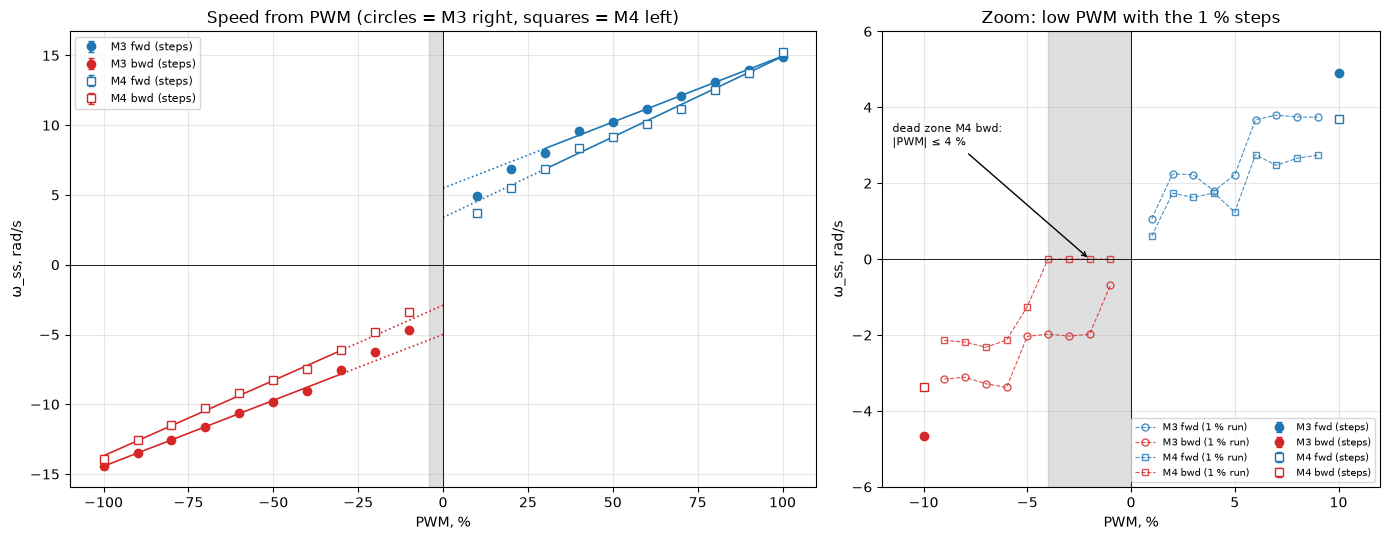

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [3, 2]})
for m in ('M3', 'M4'):
    tb = tab['steps_' + m]
    for d, sign in (('fwd', 1), ('bwd', -1)):
        side = np.sign(tb.PWM) == sign
        p = par[m, d]
        for ax in (ax1, ax2):
            ax.errorbar(tb.PWM[side], tb.w_ss[side], yerr=tb.w_err[side], fmt=MARKER[m], ms=6,
                        color=DIR_COLOR[d], mfc=DIR_COLOR[d] if m == 'M3' else 'white', capsize=2,
                        label=f'{m} {d} (steps)')
        x = np.array([LINEAR_FROM, 100]) * sign
        ax1.plot(x, p['slope'] * x + p['b'], '-', color=DIR_COLOR[d], lw=1.2)                # fitted part
        x0 = np.array([0, LINEAR_FROM]) * sign
        ax1.plot(x0, p['slope'] * x0 + p['b'], ':', color=DIR_COLOR[d], lw=1.2)              # line extended to 0
        fr = fine[m][np.sign(fine[m].PWM) == sign]
        ax2.plot(fr.PWM, fr.w_end, MARKER[m] + '--', ms=5, lw=0.8, color=DIR_COLOR[d],
                 mfc='none', alpha=0.8, label=f'{m} {d} (1 % run)')
for (m, d), p in par.items():
    dz = p['dead zone, %']
    if dz > 0:                                             # shade the dead zone
        sign = 1 if d == 'fwd' else -1
        for ax in (ax1, ax2):
            ax.axvspan(min(0, sign * dz), max(0, sign * dz), color='grey', alpha=0.25)
        ax2.annotate(f'dead zone {m} {d}:\n|PWM| ≤ {dz:.0f} %', xy=(sign * dz / 2, 0), xytext=(-11.5, 3.0),
                     fontsize=8, arrowprops={'arrowstyle': '->'})
for ax in (ax1, ax2):
    ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
    ax.set_xlabel('PWM, %'); ax.set_ylabel('ω_ss, rad/s')
ax1.set_title('Speed from PWM (circles = M3 right, squares = M4 left)')
ax2.set_title('Zoom: low PWM with the 1 % steps')
ax2.set_xlim(-12, 12); ax2.set_ylim(-6, 6)
ax1.legend(fontsize=8, loc='upper left'); ax2.legend(fontsize=7, loc='lower right', ncol=2)
plt.tight_layout()
plt.show()

**Figure 2.** Speed from PWM, $\omega_{ss}$(PWM), both motors on the same axes (circles = M3 right, squares = M4 left). Forward is blue, backward is red. Solid lines are the straight-line fits over |PWM| ≥ 30 %. Dotted lines are the same lines extended to PWM = 0, to show the offset $b$. The grey band is the dead zone (only M4 backward, −4 … 0 %). Right: zoom with the 1 % run (hollow markers). The error bars (s.e. from `curve_fit`) are smaller than the markers.

In the zoom I see that at low PWM the speed does not grow smoothly. It changes in steps: for M3, 2–5 % give about the same speed (≈ 2 rad/s), 6–9 % give ≈ 3.1–3.8 rad/s, and 10 % gives 4.7–4.9 rad/s. M4 does the same at a lower level. I think the motor driver cannot make every small PWM value exactly.

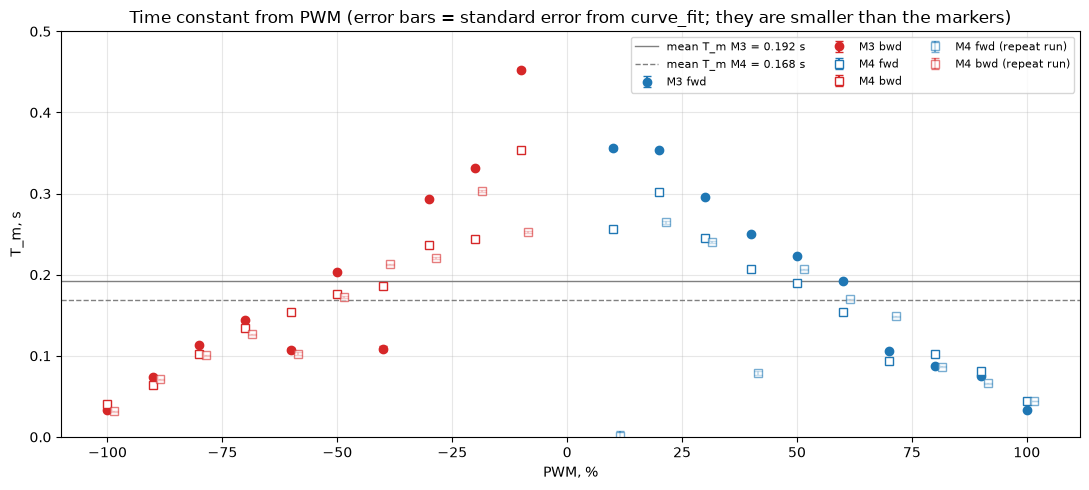

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
for name, filled in (('steps_M3', True), ('steps_M4', True), ('steps_M4_repeat', False)):
    m = name[6:8]
    tb = tab[name]
    for d, sign in (('fwd', 1), ('bwd', -1)):
        side = np.sign(tb.PWM) == sign
        lab = f'{m} {d}' + (' (repeat run)' if 'repeat' in name else '')
        ax.errorbar(tb.PWM[side] + (1.5 if 'repeat' in name else 0), tb.T_m[side], yerr=tb.T_m_err[side],
                    fmt=MARKER[m], ms=6, capsize=3, color=DIR_COLOR[d],
                    mfc=DIR_COLOR[d] if (filled and m == 'M3') else 'white', alpha=1 if filled else 0.6, label=lab)
for m, ls in (('M3', '-'), ('M4', '--')):
    mean_all = tab['steps_' + m].T_m.mean()
    ax.axhline(mean_all, color='grey', ls=ls, lw=1, label=f'mean T_m {m} = {mean_all:.3f} s')
ax.set_xlabel('PWM, %'); ax.set_ylabel('T_m, s')
ax.set_title('Time constant from PWM (error bars = standard error from curve_fit; they are smaller than the markers)')
ax.set_ylim(0, 0.5)
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

**Figure 3.** Time constant $T_m$ from PWM for both motors, with error bars from `curve_fit` (smaller than the markers). Light hollow markers are the repeated M4 run (shifted by +1.5 % so that they do not hide the others). Horizontal lines are the mean $T_m$ of each motor.

**Is $T_m$ really constant?** No. $T_m$ clearly depends on PWM. It is 0.26–0.45 s at ±10 % and only 0.03–0.04 s at ±100 %, about 10 times shorter. So the mean value (0.17–0.20 s) is not very useful alone, because $T_m$ changes by ±0.09–0.13 s around it. A few points are lower than their neighbours (M3 −60 %, −40 %, +70 %; repeated M4 +10 %, +40 %). In these steps the speed jumps at the first samples (Section 5.6), and one exponential cannot follow such a start. The two M4 runs also show that $T_m$ at one level can change by up to about 60 % between runs, much more than the error bars. The fit for the repeated M4 run at +10 % failed ($T_m$ = 0.001 s, the lower limit), so this point is at zero.

My explanation: the TRIK driver switches the battery on and off (PWM). In Section 5.5 I show that with PWM = 0 the motor is not braked: the wheel rolls freely and only friction stops it. So at low PWM the motor gets voltage only for a short part of each PWM period, and the rest of the time it rolls freely. That is why it needs more time to reach its speed, and $T_m$ is large. At 100 % the motor is always connected and $T_m$ is the shortest (0.03–0.04 s). This is the closest to the real electromechanical time constant. The same effect explains the big offset $b$: between the pulses the motor is not slowed down, so even a small PWM gives quite a high speed. So the model assumption "$T_m$ = const" is not true for my motors.

### 4.4 Complex signals: model versus real motor

I simulate the motor with `odeint`, like in the course notebook. The input is not a constant: I interpolate the recorded PWM with `np.interp(t, t_log, pwm_log)`. I set `hmax = 5 ms`, so that `odeint` does not jump over the fast PWM changes. I compare three models:

| Model | Steady-state speed | Time constant | When PWM = 0 |
|---|---|---|---|
| 1. Course model | $\omega_{ss} = U/k_e$, $k_e$ from the slope (one value per direction) | mean $T_m$ of the motor | slows down with $T_m$ |
| 2. Course model + dead zone | the same, but $U = 0$ when \|PWM\| ≤ dead zone | mean $T_m$ | slows down with $T_m$ |
| 3. My improved model | my measured curve $\omega_{ss}$(PWM) from Figure 2 (`np.interp` between all measured points and (0, 0)). It contains the offset $b$ and the dead zone. | mean $T_m$ | the wheel only coasts, with $T_{coast}$ |

$T_{coast}$ is the time constant of free rolling after power-off. I get it from the coasting parts of the step series. For an exponential slow-down from speed $\omega$ the wheel turns $\omega\,T_{coast}$, so $T_{coast}$ = coasting angle / $\omega_{ss}$ (median over all levels). This is a simplification: in Section 5.5 the real slow-down is closer to a straight line, but the exponential gives the right coasting angle.

Measured speed: `np.gradient` of the angle, then a centred moving average with a window of 3 samples (about 90 ms in these files).
Metrics: RMSE and fit $= 100\,(1 - \lVert y - \hat y\rVert / \lVert y - \bar y\rVert)$, for the angle and for the speed.

In [8]:
# Coasting time constant: when PWM = 0 the wheel rolls on (Section 5.5).
# For an exponential slow-down from speed w, the coasting angle is w * T_coast, so T_coast = angle / w.
T_COAST = {}
for m in ('M3', 'M4'):
    tb = tab['steps_' + m]
    T_COAST[m] = np.median(np.abs(tb.coast / tb.w_ss))
    print(f'{m}: T_coast = {T_COAST[m]:.3f} s   (mean T_m with power on = {tb.T_m.mean():.3f} s)')

# Speed curve for the improved model: all my measured points + (0, 0)
CURVE = {}
for m in ('M3', 'M4'):
    pwm_pts = np.r_[tab['steps_' + m].PWM, fine[m].PWM, 0.0]
    w_pts = np.r_[tab['steps_' + m].w_ss, fine[m].w_end, 0.0]
    order = np.argsort(pwm_pts)
    CURVE[m] = (pwm_pts[order], w_pts[order])

M3: T_coast = 0.358 s   (mean T_m with power on = 0.192 s)
M4: T_coast = 0.260 s   (mean T_m with power on = 0.168 s)


In [9]:
def make_motor(m, kind):
    """Right-hand side for odeint. kind = 'course', 'course + dead zone' or 'improved'."""
    T_m = tab['steps_' + m].T_m.mean()                      # one mean T_m for the motor
    def motor(state, t, t_log, pwm_log):
        speed, angle = state
        pwm = np.interp(t, t_log, pwm_log)                   # recorded input, %
        d = 'fwd' if pwm > 0 else 'bwd'
        if kind in ('course', 'course + dead zone'):
            U = pwm / 100 * U_BAT                            # recorded input, converted to volts
            if kind == 'course + dead zone' and abs(pwm) <= par[m, d]['dead zone, %']:
                U = 0.0                                      # inside the dead zone the motor does not move
            return np.array([-speed / T_m + U / (T_m * par[m, d]['k_e']), speed])
        w_target = np.interp(pwm, *CURVE[m])                 # my measured speed curve (offset + dead zone)
        T = T_m if w_target != 0 else T_COAST[m]             # PWM 0 or dead zone: the wheel only coasts
        return np.array([(w_target - speed) / T, speed])
    return motor

def smooth(x, window=3):                                     # centred moving average
    return pd.Series(x).rolling(window, center=True, min_periods=1).mean().to_numpy()

def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))

def fit_percent(y, y_hat):
    return 100 * (1 - np.linalg.norm(y - y_hat) / np.linalg.norm(y - np.mean(y)))

MODELS = ['course', 'course + dead zone', 'improved']
sim, meas, results = {}, {}, []
for sig in ('square', 'chirp'):
    for m in ('M3', 'M4'):
        theta, t, pwm = raw[f'{sig}_{m}']
        t_log, th = t - t[0], theta - theta[0]                   # time and angle from the start of the run
        w_meas = smooth(np.gradient(th, t_log), 3)              # measured speed, moving average of 3 samples
        meas[sig, m] = (t_log, th, w_meas, pwm)
        for kind in MODELS:
            y = odeint(make_motor(m, kind), [0, 0], t_log, args=(t_log, pwm), hmax=0.005)
            sim[sig, m, kind] = y
            results.append([sig, m, kind, rmse(th, y[:, 1]), fit_percent(th, y[:, 1]),
                            rmse(w_meas, y[:, 0]), fit_percent(w_meas, y[:, 0])])
res = pd.DataFrame(results, columns=['signal', 'motor', 'model', 'angle RMSE, rad', 'angle fit, %',
                                     'speed RMSE, rad/s', 'speed fit, %'])
display(res.round(2))

# Where does the angle error come from? Distance turned forward and backward while the signal is on
for sig in ('square', 'chirp'):
    for m in ('M3', 'M4'):
        t_log, th, w_meas, pwm = meas[sig, m]
        on = t_log < 8.0
        d_meas, d_sim = np.diff(th[on]), np.diff(sim[sig, m, 'improved'][on, 1])
        f_m, f_s = d_meas[d_meas > 0].sum(), d_sim[d_sim > 0].sum()
        b_m, b_s = -d_meas[d_meas < 0].sum(), -d_sim[d_sim < 0].sum()
        print(f'{sig} {m}, improved model: forward {f_s:.1f} rad (measured {f_m:.1f}, {100 * (f_s / f_m - 1):+.0f} %), '
              f'backward {b_s:.1f} rad (measured {b_m:.1f}, {100 * (b_s / b_m - 1):+.0f} %)')

,signal,motor,model,"angle RMSE, rad","angle fit, %","speed RMSE, rad/s","speed fit, %"
0,square,M3,course,2.24,-46.16,3.12,49.12
1,square,M3,course + dead zone,2.24,-46.16,3.12,49.12
2,square,M3,improved,0.39,74.54,0.67,89.05
3,square,M4,course,0.87,32.73,1.89,66.92
4,square,M4,course + dead zone,0.87,32.83,1.89,66.92
5,square,M4,improved,0.92,28.59,0.63,88.95
6,chirp,M3,course,3.78,-157.72,1.79,44.72
7,chirp,M3,course + dead zone,3.78,-157.72,1.79,44.72
8,chirp,M3,improved,0.53,64.18,0.74,77.11
9,chirp,M4,course,2.38,-72.05,1.32,57.91


square M3, improved model: forward 25.1 rad (measured 26.0, -4 %), backward 20.9 rad (measured 22.4, -7 %)
square M4, improved model: forward 24.3 rad (measured 24.3, -0 %), backward 19.8 rad (measured 21.3, -7 %)
chirp M3, improved model: forward 15.4 rad (measured 15.6, -1 %), backward 8.4 rad (measured 8.6, -2 %)
chirp M4, improved model: forward 15.3 rad (measured 15.1, +1 %), backward 7.2 rad (measured 8.6, -16 %)


Results:
- Model 1 is very bad: the angle fit is −46 % (square) and −158 % (chirp) for M3. At 60 % PWM, $U/k_e$ gives only about half of the real speed for M3 and about 70 % for M4, because the real speed line has the offset $b$ (Figure 2). In Figures 4 and 5 the orange dotted lines move much too slowly.
- Model 2 is almost the same as Model 1. Adding the dead zone changes nothing for M3 (its dead zone is 0) and changes the fit by less than 1.5 % for M4 (4 % dead zone backward). My dead zone is too small to matter.
- Model 3 is much better for the speed: the speed fit is 89 % on the square wave for both motors and 77 % / 75 % on the chirp (M3 / M4). The angle fit is 75 % / 29 % on the square and 64 % / 31 % on the chirp. For the angle, Model 3 is better in three of the four cases. On the M4 square wave it is a little lower than Model 2 (29 % vs 33 %, see below).
- The lines under the table show where the angle error comes from. For M4 the improved model turns forward almost exactly like the real wheel, but backward it turns 7 % (square) and 16 % (chirp) less.

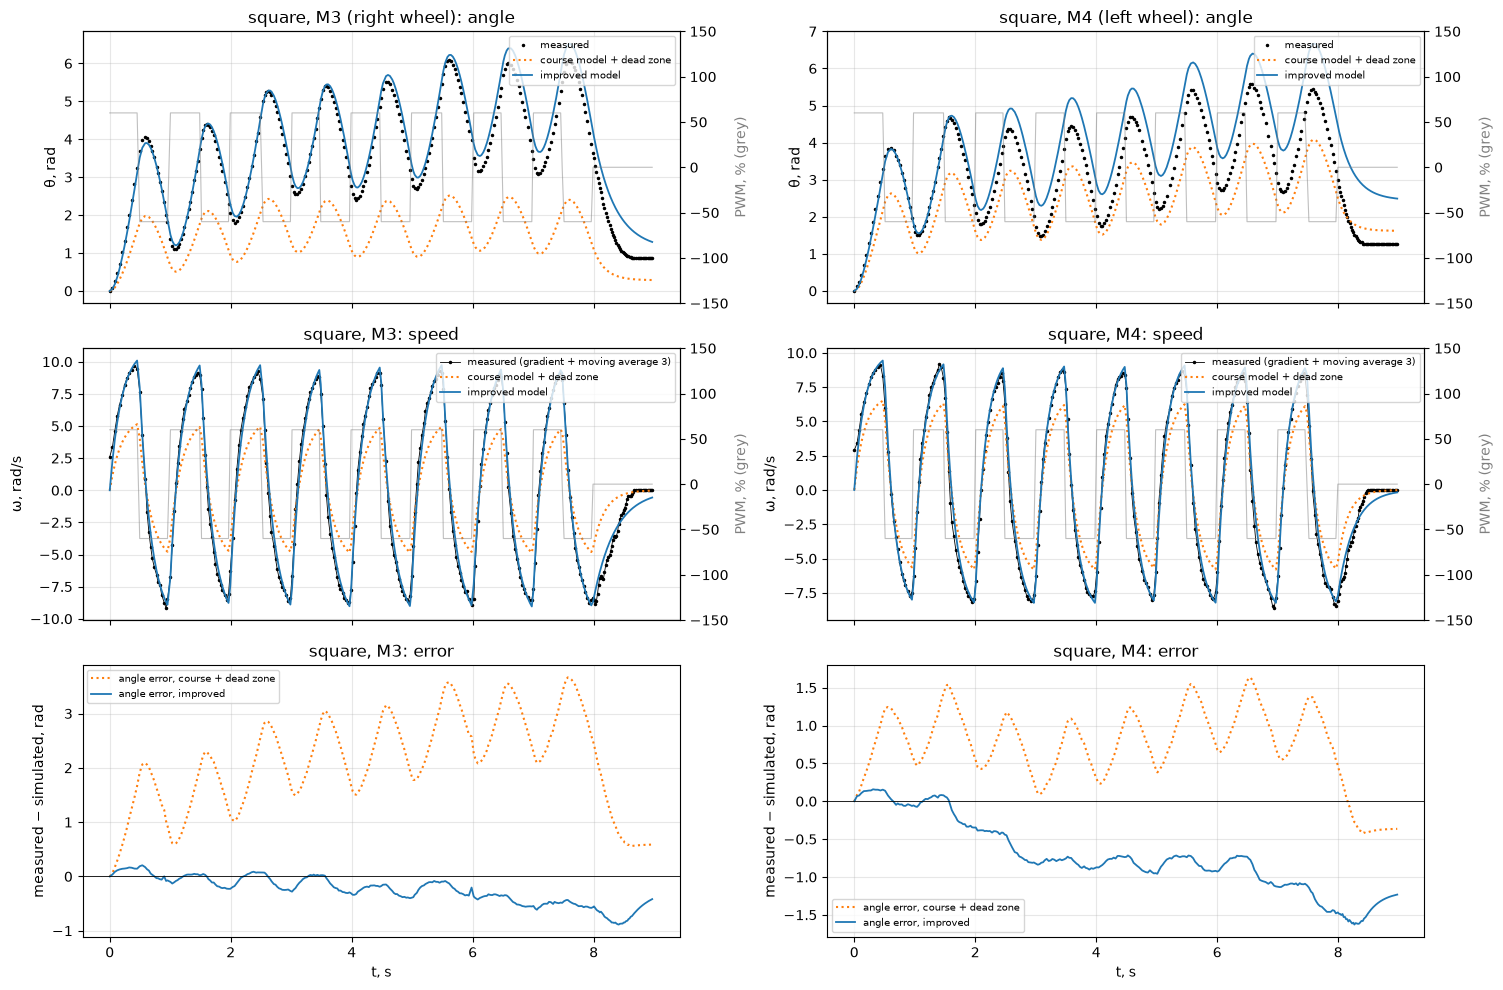

In [10]:
def plot_signal(sig):
    fig, axs = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
    for col, m in enumerate(('M3', 'M4')):
        t_log, th, w_meas, pwm = meas[sig, m]
        y_c, y_i = sim[sig, m, 'course + dead zone'], sim[sig, m, 'improved']
        ax = axs[0, col]
        ax.plot(t_log, th, 'k.', ms=3, label='measured')
        ax.plot(t_log, y_c[:, 1], ':', color='tab:orange', lw=1.5, label='course model + dead zone')
        ax.plot(t_log, y_i[:, 1], '-', color='tab:blue', lw=1.3, label='improved model')
        ax.set_ylabel('θ, rad'); ax.set_title(f'{sig}, {m} ({WHEEL[m]}): angle')
        ax = axs[1, col]
        ax.plot(t_log, w_meas, 'k.-', ms=3, lw=0.6, label='measured (gradient + moving average 3)')
        ax.plot(t_log, y_c[:, 0], ':', color='tab:orange', lw=1.5, label='course model + dead zone')
        ax.plot(t_log, y_i[:, 0], '-', color='tab:blue', lw=1.3, label='improved model')
        ax.set_ylabel('ω, rad/s'); ax.set_title(f'{sig}, {m}: speed')
        for ax in axs[:2, col]:
            ax2 = ax.twinx()
            ax2.plot(t_log, pwm, color='grey', lw=0.8, alpha=0.5)
            ax2.set_ylabel('PWM, % (grey)', color='grey'); ax2.set_ylim(-150, 150); ax2.grid(False)
            ax.legend(fontsize=7, loc='upper right')
        ax = axs[2, col]
        ax.plot(t_log, th - y_c[:, 1], ':', color='tab:orange', lw=1.5, label='angle error, course + dead zone')
        ax.plot(t_log, th - y_i[:, 1], '-', color='tab:blue', lw=1.3, label='angle error, improved')
        ax.axhline(0, color='k', lw=0.6)
        ax.set_ylabel('measured − simulated, rad'); ax.set_xlabel('t, s'); ax.set_title(f'{sig}, {m}: error')
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

plot_signal('square')

**Figure 4.** Square wave (±60 %, P = 1 s): measured vs simulated angle (top) and speed (middle), with the input PWM on the second axis (grey). Bottom: angle error, measured − simulated. Left M3, right M4. Orange dotted = course model + dead zone, blue = improved model.

The improved model follows the speed very well, also during the fast reversals. The angle error grows slowly. For M3 it stays small: −0.6 rad at t = 8 s, which is about 1 % of the total distance the wheel turned. For M4 it reaches about −1.5 rad at t = 8 s. The model turns forward correctly, but backward it turns 7 % less than the real wheel. This is much more than the difference between my two M4 step runs (about 1 %), so it is a real error of the model, not noise. I think the backward motion of M4 in fast reversals is different from the step tests, which always start from rest, but I could not find the exact reason in my data.

At the end (t > 8 s, PWM = 0) the improved model coasts much more like the real wheel than the course model. But its exponential slow-down is a bit too long: the real wheel stops at about 8.6 s, because its speed falls along a straight line (Section 5.5).

For square M4 the angle fit of the course model (33 %) is even a bit higher than for the improved model (29 %), although its speed amplitude is clearly wrong (about 70 % of the real one). A small drift makes the angle fit low, even when the speed is good. So I also give the speed fit.

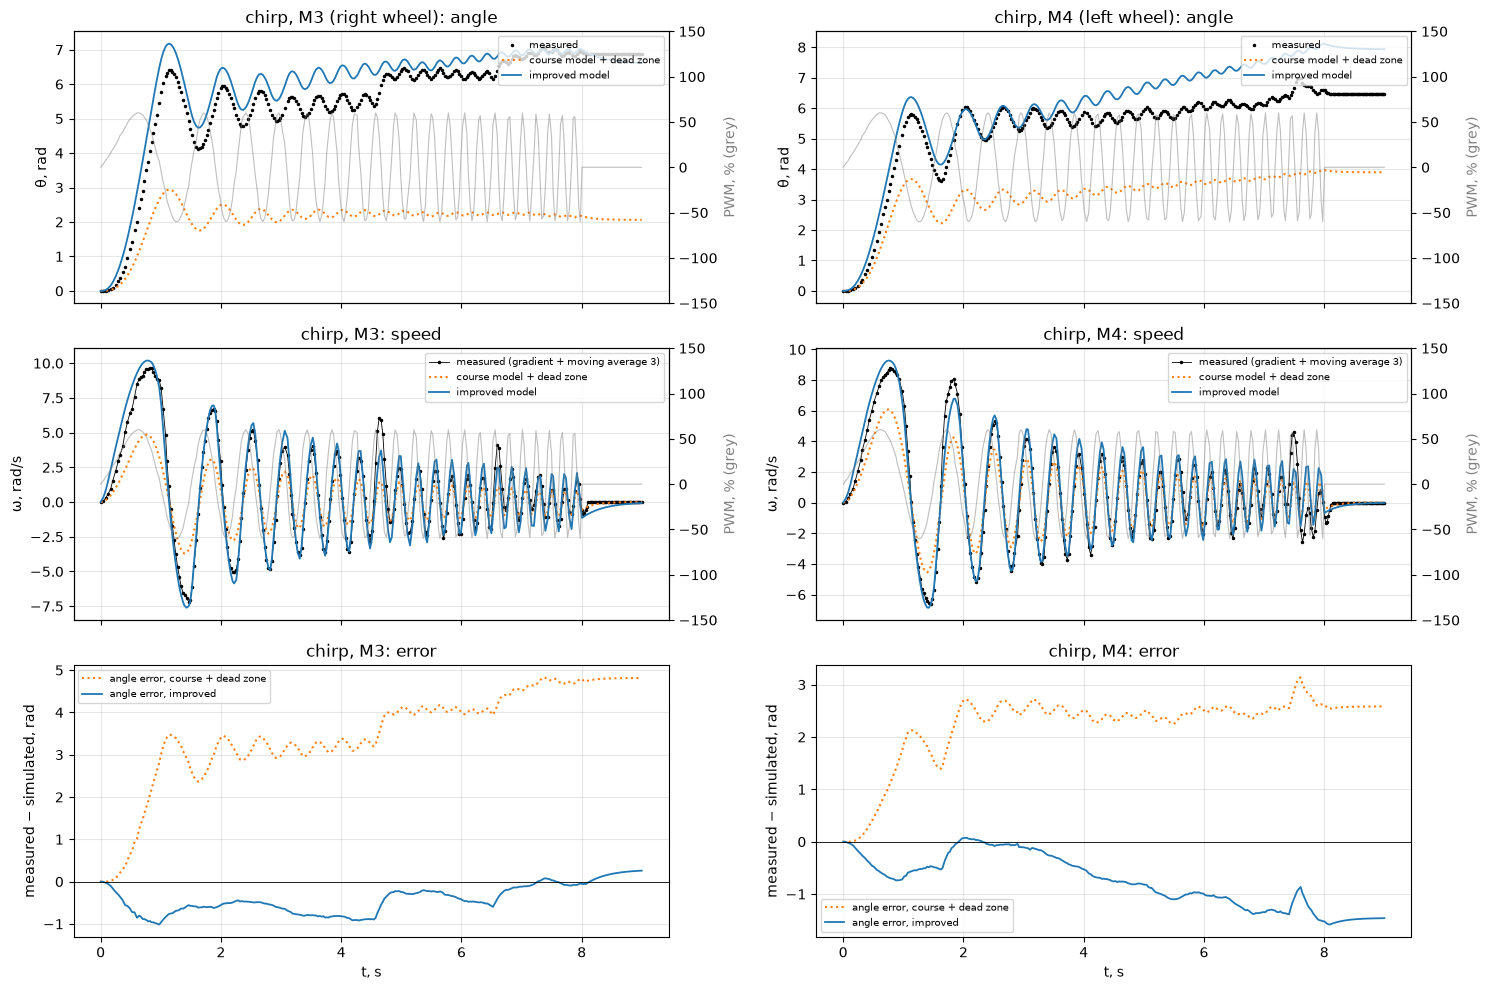

In [11]:
plot_signal('chirp')

**Figure 5.** Chirp (60 %, 0.2 → 5 Hz in 8 s): measured vs simulated angle and speed with the input PWM (grey), and the angle error. Same colours as in Figure 4.

Where is the error largest?
1. In the first second. The PWM grows slowly from 0, and at low PWM the real motor speeds up more slowly than the model (its $T_m$ is 0.3–0.45 s there, but the model uses the mean 0.17–0.19 s). During the first lobe the model is up to 1 rad ahead of the measurement, and its first peak is 0.6–0.8 rad too high.
2. Short jumps at t ≈ 4.6 s (M3) and t ≈ 7.5 s (M4). Here the measured speed has one bigger peak that the model does not have, although the PWM in this period looks like in the periods before. I could not find the reason in the input. I think it is a mechanical effect, maybe the gear backlash.
3. A slow drift for M4, like in the square wave: the model turns backward 16 % less than the real wheel.

At high frequency (> 3 Hz) the speed amplitude of the improved model is close to the measurement.

M3: T_m from the chirp = 0.182 ± 0.027 s (mean T_m of the steps = 0.192 s); K = 1.59 rad/s per V, so k_e = 1/K = 0.63 V·s/rad; ratio at 0.69 Hz = 1.24, at 4.84 Hz = 0.24 rad/s per V
M4: T_m from the chirp = 0.183 ± 0.029 s (mean T_m of the steps = 0.168 s); K = 1.57 rad/s per V, so k_e = 1/K = 0.64 V·s/rad; ratio at 0.69 Hz = 1.16, at 4.84 Hz = 0.16 rad/s per V


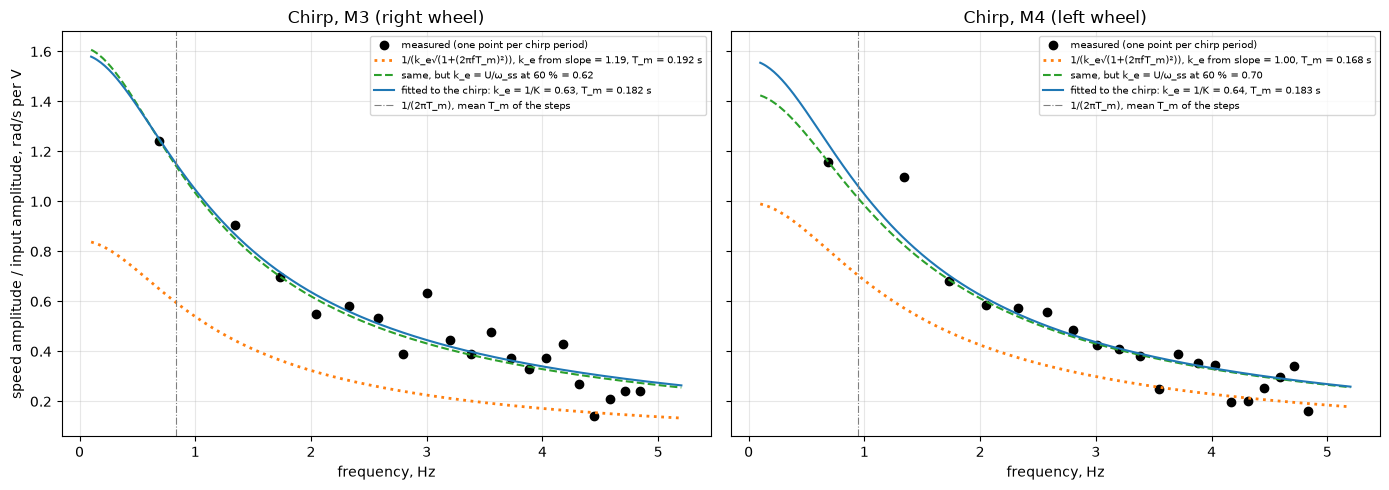

In [12]:
A, F0, F1, T_CH = 60, 0.2, 5.0, 8.0           # chirp settings in my program (%, Hz, Hz, s)
U_amp = A / 100 * U_BAT                       # input amplitude, V
f_line = np.linspace(0.1, 5.2, 300)

def gain(f, K, T_m):                          # first-order model: speed amplitude / voltage amplitude
    return K / np.sqrt(1 + (2 * np.pi * f * T_m) ** 2)

fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
chirp_fit = {}
for ax, m in zip(axs, ('M3', 'M4')):
    t_log, th, w_meas, pwm = meas['chirp', m]
    phase = F0 * t_log + (F1 - F0) * t_log ** 2 / (2 * T_CH)      # number of chirp periods since the start
    f_pts, ratio = [], []
    for k in range(int(phase[t_log < T_CH].max())):               # only full periods
        sel = (phase >= k) & (phase < k + 1)
        tt, aa = t_log[sel], th[sel]
        f = F0 + (F1 - F0) * tt.mean() / T_CH                     # frequency in the middle of this period, Hz
        swing = np.ptp(aa - np.polyval(np.polyfit(tt, aa, 1), tt))    # angle swing without the slow drift, rad
        f_pts.append(f)
        ratio.append(np.pi * f * swing / U_amp)                   # speed amplitude = 2*pi*f * swing/2
    f_pts, ratio = np.array(f_pts), np.array(ratio)
    (K, T_fit), pcov = optimize.curve_fit(gain, f_pts, ratio, p0=[1.5, 0.15])
    chirp_fit[m] = (K, T_fit, np.sqrt(pcov[1, 1]))
    T_m = tab['steps_' + m].T_m.mean()
    k_e = np.mean([par[m, d]['k_e'] for d in ('fwd', 'bwd')])
    w60 = np.mean([abs(np.interp(s * 60, *CURVE[m])) for s in (1, -1)])   # measured w_ss at ±60 %
    ax.plot(f_pts, ratio, 'ko', label='measured (one point per chirp period)')
    ax.plot(f_line, gain(f_line, 1 / k_e, T_m), ':', color='tab:orange', lw=2,
            label=f'1/(k_e√(1+(2πfT_m)²)), k_e from slope = {k_e:.2f}, T_m = {T_m:.3f} s')
    ax.plot(f_line, gain(f_line, w60 / U_amp, T_m), '--', color='tab:green', lw=1.5,
            label=f'same, but k_e = U/ω_ss at 60 % = {U_amp / w60:.2f}')
    ax.plot(f_line, gain(f_line, K, T_fit), '-', color='tab:blue', lw=1.5,
            label=f'fitted to the chirp: k_e = 1/K = {1 / K:.2f}, T_m = {T_fit:.3f} s')
    ax.axvline(1 / (2 * np.pi * T_m), color='grey', lw=0.8, ls='-.', label='1/(2πT_m), mean T_m of the steps')
    ax.set_xlabel('frequency, Hz'); ax.set_title(f'Chirp, {m} ({WHEEL[m]})')
    ax.legend(fontsize=7)
    print(f'{m}: T_m from the chirp = {T_fit:.3f} ± {np.sqrt(pcov[1, 1]):.3f} s (mean T_m of the steps = {T_m:.3f} s); '
          f'K = {K:.2f} rad/s per V, so k_e = 1/K = {1 / K:.2f} V·s/rad; ratio at {f_pts[0]:.2f} Hz = {ratio[0]:.2f}, '
          f'at {f_pts[-1]:.2f} Hz = {ratio[-1]:.2f} rad/s per V')
axs[0].set_ylabel('speed amplitude / input amplitude, rad/s per V')
plt.tight_layout()
plt.show()

**Figure 6.** Chirp: ratio of speed amplitude to input amplitude against frequency. Black dots: measured, one point per chirp period. Orange dotted: the formula $1/(k_e\sqrt{1 + (2\pi f T_m)^2})$ with $k_e$ from the slope and the mean $T_m$ of the steps. Green dashed: the same formula with $k_e = U/\omega_{ss}$ at 60 %. Blue: the formula fitted to the measured points.

How I got the measured points: for a sine, the angle swings by $\pm W/(2\pi f)$ when the speed swings by $\pm W$. So in every chirp period I take the swing of the angle (after removing the slow drift), and I get $W = 2\pi f\cdot\text{swing}/2$. I use the angle and not the noisy speed, because at 5 Hz one period has only 6–7 samples.

Result: the amplitude falls with frequency, as the first-order model says. The fitted $T_m$ is 0.182 ± 0.027 s (M3) and 0.183 ± 0.029 s (M4). This is the same as the mean $T_m$ of my steps (0.19 s and 0.17 s) within the error, so it is a direct check of $T_m$. But the formula with $k_e$ from the slope (orange) is 1.6–1.9 times too low. The motor gives about 1.6 rad/s per volt at low frequency, so $k_e \approx 0.63$ V·s/rad, not 0.97–1.19. The reason is again the offset $b$. With $k_e = U/\omega_{ss}$ at 60 % (0.62–0.70 V·s/rad, green line) the formula is close to my points. The points above 4 Hz scatter more, because the PWM is updated only every ~30 ms and the angle swing is only a few encoder steps there.

## 5. Artifact analysis

### 5.1 Forward vs backward asymmetry

In [13]:
def pct(a, b):                                  # difference of a and b in % of their mean
    return 100 * (abs(a) - abs(b)) / ((abs(a) + abs(b)) / 2)

rows = []
for m in ('M3', 'M4'):
    tb = tab['steps_' + m]
    w = dict(zip(tb.PWM, tb.w_ss))
    f, b = par[m, 'fwd'], par[m, 'bwd']
    rows.append([m, 'slope, rad/s per %', f['slope'], b['slope'], pct(f['slope'], b['slope'])])
    rows.append([m, 'offset b, rad/s', f['b'], b['b'], pct(f['b'], b['b'])])
    rows.append([m, 'k_e, V·s/rad', f['k_e'], b['k_e'], pct(f['k_e'], b['k_e'])])
    for lv in (10, 60, 100):
        rows.append([m, f'ω_ss at ±{lv} %, rad/s', w[lv], w[-lv], pct(w[lv], w[-lv])])
    rows.append([m, 'mean T_m, s', f['T_m'], b['T_m'], pct(f['T_m'], b['T_m'])])
    rows.append([m, 'dead zone, %', f['dead zone, %'], b['dead zone, %'], np.nan])
asym = pd.DataFrame(rows, columns=['motor', 'quantity', 'forward', 'backward', 'forward − backward, %'])
display(asym.round(3))
for name in ('steps_M3', 'steps_M4', 'steps_M4_repeat'):
    theta, t, pwm = raw[name]
    print(f'{name}: angle at the end of the whole series = {np.rad2deg(theta[-1]):.0f} deg ({theta[-1]:.2f} rad)')

,motor,quantity,forward,backward,"forward − backward, %"
0,M3,"slope, rad/s per %",0.095,0.094,0.182
1,M3,"offset b, rad/s",5.490,-4.998,9.394
2,M3,"k_e, V·s/rad",1.184,1.186,-0.182
3,M3,"ω_ss at ±10 %, rad/s",4.895,-4.665,4.811
4,M3,"ω_ss at ±60 %, rad/s",11.147,-10.607,4.970
5,M3,"ω_ss at ±100 %, rad/s",14.918,-14.395,3.566
6,M3,"mean T_m, s",0.197,0.186,5.661
7,M3,"dead zone, %",0.000,0.000,NaN
8,M4,"slope, rad/s per %",0.115,0.108,6.770
9,M4,"offset b, rad/s",3.383,-2.903,15.260


steps_M3: angle at the end of the whole series = 732 deg (12.78 rad)
steps_M4: angle at the end of the whole series = 1235 deg (21.55 rad)
steps_M4_repeat: angle at the end of the whole series = 1343 deg (23.44 rad)


Both motors turn faster forward than backward at the same |PWM|: M3 by 3.5–5 %, M4 by about 9 %. For M3 the slopes are the same (0.2 % difference), so the difference comes from the offset $b$ (9 %). For M4 both the slope (7 %) and the offset (15 %) are different, and only M4 backward has a dead zone (4 %). $T_m$ is almost the same in both directions (6 % for M3, 1 % for M4). This is small compared with its change over PWM.

Because forward is faster, the wheel does not come back to zero after the symmetric series. The final angle is +732° (M3) and +1235° / +1343° (M4, two runs). This is not encoder drift, it is the asymmetry. Possible physical reasons: the motor brushes may work a little better in one direction, the gearbox friction can be different in the two directions, and the driver may not be perfectly symmetric.

### 5.2 Zero drift

steps_M3        : zero block 2.98 s, 140 samples, encoder min/max = 0/0 deg, first time() = 43 ms
steps_M4        : zero block 2.99 s, 146 samples, encoder min/max = 0/0 deg, first time() = 38 ms
steps_M4_repeat : zero block 3.00 s, 140 samples, encoder min/max = 0/0 deg, first time() = 36 ms
deadzone_M3     : zero block 2.98 s, 138 samples, encoder min/max = 0/0 deg, first time() = 43 ms
deadzone_M4     : zero block 2.96 s, 140 samples, encoder min/max = 0/0 deg, first time() = 27 ms
steps_M3        : angle change in the last 0.3 s of each coasting part (deg): [-10, 0, -8, -4, -1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 9, 20, 1, 32]
steps_M4        : angle change in the last 0.3 s of each coasting part (deg): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 9]
steps_M4_repeat : angle change in the last 0.3 s of each coasting part (deg): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5, 0]
deadzone_M3     : angle change in the last 0.3 s of each coasting part (deg): [0, 0, 0

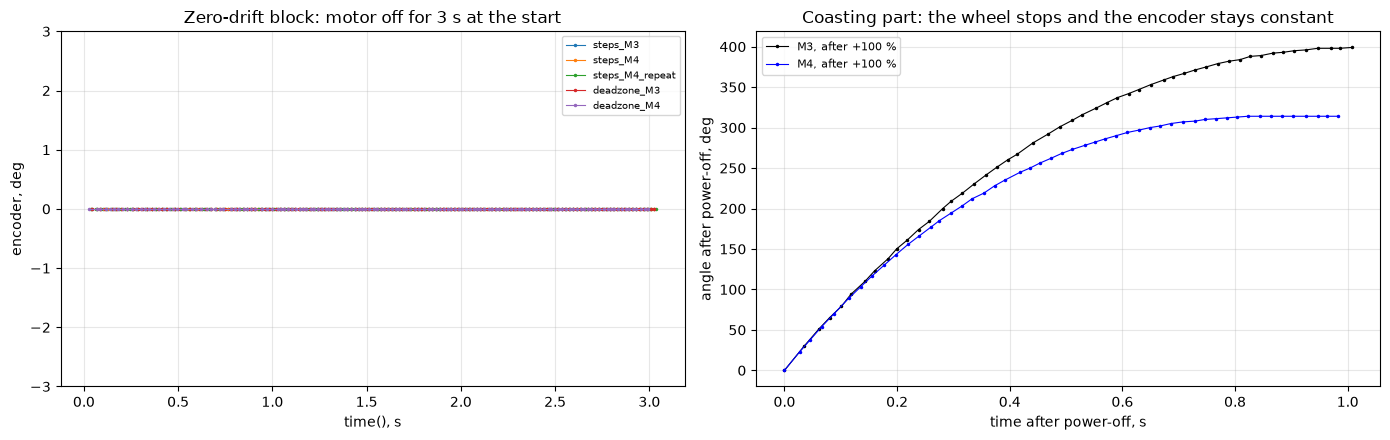

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for name in ('steps_M3', 'steps_M4', 'steps_M4_repeat', 'deadzone_M3', 'deadzone_M4'):
    theta, t, pwm = raw[name]
    first = np.argmax(pwm != 0)                       # first row with the motor on
    ax1.plot(t[:first], np.rad2deg(theta[:first]), '.-', ms=3, lw=0.8, label=name)
    print(f'{name:16s}: zero block {t[first - 1] - t[0]:.2f} s, {first} samples, '
          f'encoder min/max = {np.rad2deg(theta[:first]).min():.0f}/{np.rad2deg(theta[:first]).max():.0f} deg, '
          f'first time() = {1000 * t[0]:.0f} ms')
ax1.set_ylim(-3, 3); ax1.set_xlabel('time(), s'); ax1.set_ylabel('encoder, deg')
ax1.set_title('Zero-drift block: motor off for 3 s at the start'); ax1.legend(fontsize=7)

# after the wheel stops: does the encoder still change? last 0.3 s of every coasting part
for name in ('steps_M3', 'steps_M4', 'steps_M4_repeat', 'deadzone_M3', 'deadzone_M4'):
    change = []
    for s in split_levels(*raw[name]):
        late = s['t_off'] > s['t_off'][-1] - 0.3
        change.append(np.rad2deg(s['theta_off'][late][-1] - s['theta_off'][late][0]))
    change = [int(round(x)) for x in change]
    print(f'{name:16s}: angle change in the last 0.3 s of each coasting part (deg): {change}')

s = [x for x in segs['steps_M3'] if x['level'] == 100][0]
ax2.plot(s['t_off'], np.rad2deg(s['theta_off']), 'k.-', ms=3, lw=0.8, label='M3, after +100 %')
s = [x for x in segs['steps_M4'] if x['level'] == 100][0]
ax2.plot(s['t_off'], np.rad2deg(s['theta_off']), 'b.-', ms=3, lw=0.8, label='M4, after +100 %')
ax2.set_xlabel('time after power-off, s'); ax2.set_ylabel('angle after power-off, deg')
ax2.set_title('Coasting part: the wheel stops and the encoder stays constant'); ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Figure 7.** Left: encoder during the 3 s zero-PWM block at the start of every step file (motor off). Right: angle after power-off at +100 % (coasting part).

With the motor off, the encoder stays exactly 0 for 3 s in all five files (138–146 samples). In the dead-zone runs the encoder also does not change in the last 0.3 s of any coasting part. In the step runs it changes only after high PWM levels, where the wheel was still rolling (M3 needs about 1 s to stop after ±100 %, Figure 7 right). So I see no encoder drift. The angle does not return to zero after the series, but this comes from the forward/backward asymmetry (5.1), not from drift.

Time offset: `time()` is already 27–43 ms (Program A) and 65–71 ms (Program B) at the first sample. I remove it by subtracting the first time of each segment.

### 5.3 Dead zone

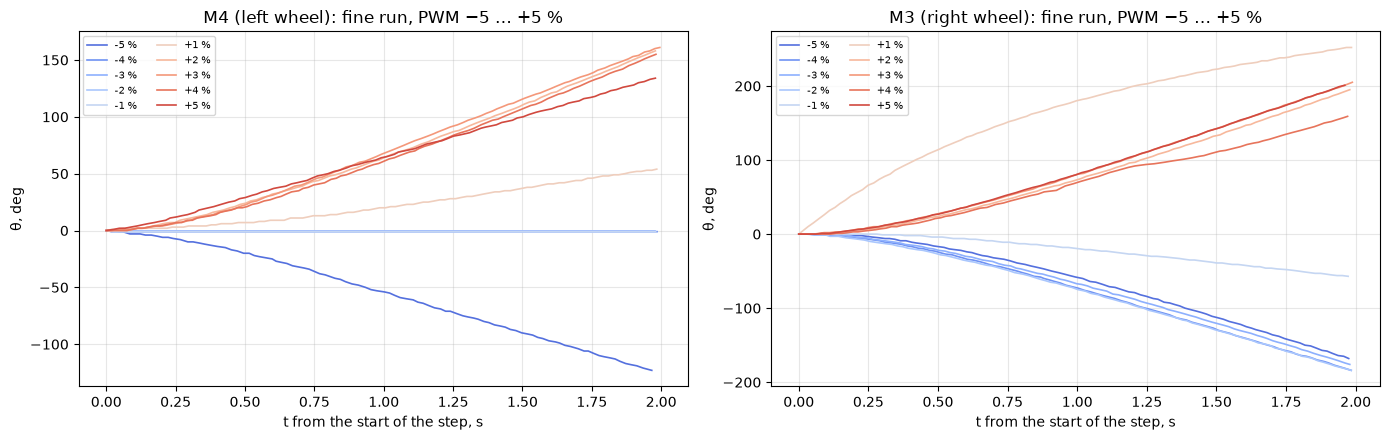

M3 fwd: dead zone = 0 % (largest |PWM| where the wheel turned less than 10 deg in 2 s)
M3 bwd: dead zone = 0 % (largest |PWM| where the wheel turned less than 10 deg in 2 s)
M4 fwd: dead zone = 0 % (largest |PWM| where the wheel turned less than 10 deg in 2 s)
M4 bwd: dead zone = 4 % (largest |PWM| where the wheel turned less than 10 deg in 2 s)


In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for m in ('M3', 'M4'):
    for s in split_levels(*raw['deadzone_' + m]):
        if abs(s['level']) <= 5:
            ax = ax1 if m == 'M4' else ax2
            ax.plot(s['t'], np.rad2deg(s['theta']), '-', lw=1.2,
                    color=plt.get_cmap('coolwarm')((s['level'] + 6) / 12), label=f"{s['level']:+.0f} %")
for ax, m in ((ax1, 'M4'), (ax2, 'M3')):
    ax.set_title(f'{m} ({WHEEL[m]}): fine run, PWM −5 … +5 %')
    ax.set_xlabel('t from the start of the step, s'); ax.set_ylabel('θ, deg'); ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()
for m in ('M3', 'M4'):
    for d in ('fwd', 'bwd'):
        print(f"{m} {d}: dead zone = {par[m, d]['dead zone, %']:.0f} % "
              f"(largest |PWM| where the wheel turned less than {MOVED} deg in 2 s)")

**Figure 8.** Angle during the 1 % run, PWM −5 … +5 %. Left: M4, right: M3.

M4 does not move at −1 … −4 % (flat lines at zero) and moves at −5 %, so its backward dead zone is 4 %. Forward it moves already at +1 % (slowly, 0.6 rad/s). M3 moves at every level, even at −1 % (but only after about 0.3 s and slowly), so its dead zone is below 1 % in both directions. These dead zones are much smaller than the ±5–15 % in the course README. I think this is because the PWM driver gives short pulses of the full battery voltage, and these pulses can break the static friction even at 1–2 %.

In the complex signals I could not see the dead zone. At 1 Hz the PWM goes through the band −4 … +4 % in about 20 ms, which is less than one sample (30 ms).

### 5.4 Saturation

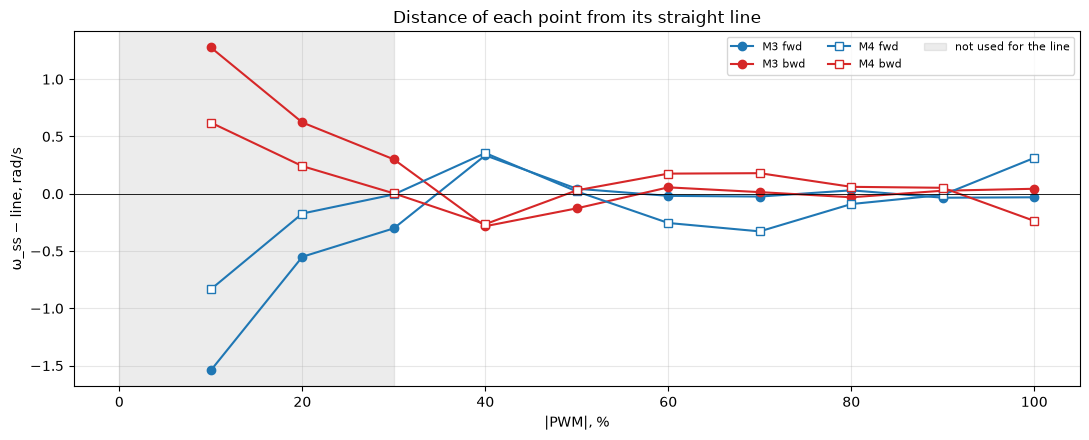

M3: speed gain per 10 % PWM:  forward 10→20 % 1.94, 50→60 % 0.88, 90→100 % 0.95 rad/s;  backward −90→−100 % 0.93 rad/s
M4: speed gain per 10 % PWM:  forward 10→20 % 1.82, 50→60 % 0.88, 90→100 % 1.48 rad/s;  backward −90→−100 % 1.37 rad/s


In [16]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for m in ('M3', 'M4'):
    tb = tab['steps_' + m]
    for d, sign in (('fwd', 1), ('bwd', -1)):
        side = np.sign(tb.PWM) == sign
        p = par[m, d]
        resid = tb.w_ss[side] - (p['slope'] * tb.PWM[side] + p['b'])
        ax.plot(tb.PWM[side].abs(), resid, MARKER[m] + '-', color=DIR_COLOR[d],
                mfc=DIR_COLOR[d] if m == 'M3' else 'white', label=f'{m} {d}')
ax.axhline(0, color='k', lw=0.6)
ax.axvspan(0, LINEAR_FROM, color='grey', alpha=0.15, label='not used for the line')
ax.set_xlabel('|PWM|, %'); ax.set_ylabel('ω_ss − line, rad/s')
ax.set_title('Distance of each point from its straight line')
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()
for m in ('M3', 'M4'):
    w = dict(zip(tab['steps_' + m].PWM, tab['steps_' + m].w_ss))
    print(f'{m}: speed gain per 10 % PWM:  forward 10→20 % {w[20] - w[10]:.2f}, 50→60 % {w[60] - w[50]:.2f}, '
          f'90→100 % {w[100] - w[90]:.2f} rad/s;  backward −90→−100 % {abs(w[-100] - w[-90]):.2f} rad/s')

**Figure 9.** Distance of every $\omega_{ss}$ point from its straight line, against |PWM|. The grey part (|PWM| < 30 %) was not used for the line.

I do not see saturation at high PWM. From 90 % to 100 % the speed still grows by 0.9–1.5 rad/s, like in the middle of the range, and the points at 100 % lie on the line (within ±0.3 rad/s). With saturation, the points at the highest PWM would be closer to zero than the line (below the line for forward, above it for backward). The real non-linearity is at low PWM: below 30 % the measured speed is up to 1.5 rad/s slower than the line (but still much faster than $U/k_e$). So for my motors the straight line is valid from 30 % to 100 %, and the biggest deviation is the jump from 0 to 10 %.

### 5.5 Coasting after power-off

M3: coasting angle 0.86 … 6.96 rad; model ω_ss·T_m 0.89 … 2.86 rad; measured/model = 1.9 (median); deceleration ω²/(2·angle) = 13.7 rad/s² (median), stop time at 100 % ≈ 1.09 s
M4: coasting angle 0.42 … 5.48 rad; model ω_ss·T_m 0.57 … 2.56 rad; measured/model = 1.5 (median); deceleration ω²/(2·angle) = 17.2 rad/s² (median), stop time at 100 % ≈ 0.89 s


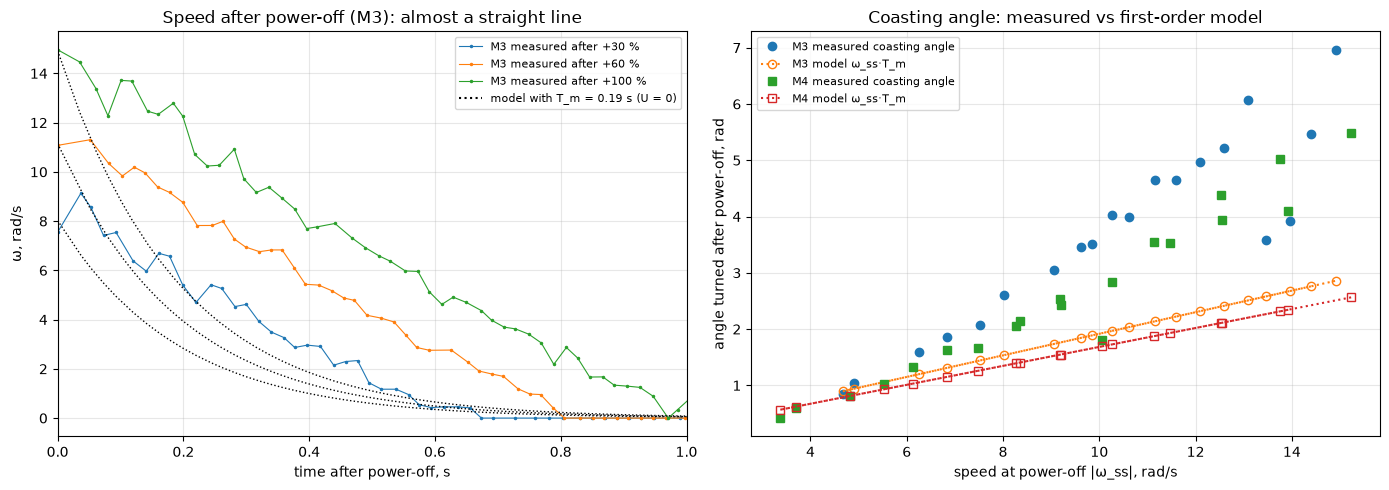

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
rows = []
for m in ('M3', 'M4'):
    T_m = tab['steps_' + m].T_m.mean()
    for s in segs['steps_' + m]:
        w0 = abs(s['w_ss'])
        coast = abs(s['theta_off'][-1])
        rows.append([m, s['level'], w0, coast, w0 * T_m, w0 ** 2 / (2 * coast)])
        if m == 'M3' and s['level'] in (30, 60, 100):
            w = np.gradient(s['theta_off'], s['t_off'])
            ax1.plot(s['t_off'], w, '.-', ms=3, lw=0.8, label=f'M3 measured after +{s["level"]:.0f} %')
            ax1.plot(s['t_off'], s['w_ss'] * np.exp(-s['t_off'] / T_m), 'k:', lw=1)
ax1.plot([], [], 'k:', label=f'model with T_m = {tab["steps_M3"].T_m.mean():.2f} s (U = 0)')
ax1.set_xlim(0, 1.0); ax1.set_xlabel('time after power-off, s'); ax1.set_ylabel('ω, rad/s')
ax1.set_title('Speed after power-off (M3): almost a straight line'); ax1.legend(fontsize=8)
co = pd.DataFrame(rows, columns=['motor', 'PWM', 'w0', 'coast', 'model', 'decel'])
for m in ('M3', 'M4'):
    c = co[co.motor == m]
    ax2.plot(c.w0, c.coast, MARKER[m], ms=6, label=f'{m} measured coasting angle')
    ax2.plot(c.w0, c.model, MARKER[m] + ':', mfc='none', label=f'{m} model ω_ss·T_m')
    print(f'{m}: coasting angle {c.coast.min():.2f} … {c.coast.max():.2f} rad; model ω_ss·T_m {c.model.min():.2f} … '
          f'{c.model.max():.2f} rad; measured/model = {np.median(c.coast / c.model):.1f} (median); '
          f'deceleration ω²/(2·angle) = {np.median(c.decel):.1f} rad/s² (median), '
          f'stop time at 100 % ≈ {c.w0.max() / np.median(c.decel):.2f} s')
ax2.set_xlabel('speed at power-off |ω_ss|, rad/s'); ax2.set_ylabel('angle turned after power-off, rad')
ax2.set_title('Coasting angle: measured vs first-order model'); ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Figure 10.** Left: speed of M3 after power-off from +30, +60 and +100 % (dots), and the first-order model with U = 0 (dotted). Right: angle turned after power-off against the speed at power-off, measured and model $\omega_{ss}T_m$.

After power-off the wheel turns 0.4–7 rad (25–400°) and needs up to about 1 s to stop. The first-order model with $U = 0$ says that the speed falls exponentially with $T_m$, so the wheel would turn only $\omega_{ss}T_m$. The measured coasting is 1.5–1.9 times longer (median), and up to 2.4 times at high speed (7.0 rad instead of 2.9 rad for M3 at +100 %). With $T_m$ at 100 % (0.033 s) the model would give only 0.5 rad. A few points coast less than the others (M3 at ±90 %, M4 at +60 %). I do not know why; maybe it depends on the position of the gears at the moment of power-off.

The shape is also different: the measured speed falls along an almost straight line, not an exponential. A straight line means a constant deceleration, about 14 rad/s² (M3) and 17 rad/s² (M4). This is dry (Coulomb) friction, not viscous friction. It also shows that with PWM = 0 the TRIK driver does not brake the motor (the motor is not short-circuited). The wheel just rolls until friction stops it. This is why I added coasting to my improved model.

### 5.6 Gear backlash

M3: 14 reversals; the measured speed crosses zero on average 18 ms earlier than the model (standard deviation 5 ms, range -25 … -6 ms)
M4: 14 reversals; the measured speed crosses zero on average 15 ms earlier than the model (standard deviation 9 ms, range -35 … +0 ms)


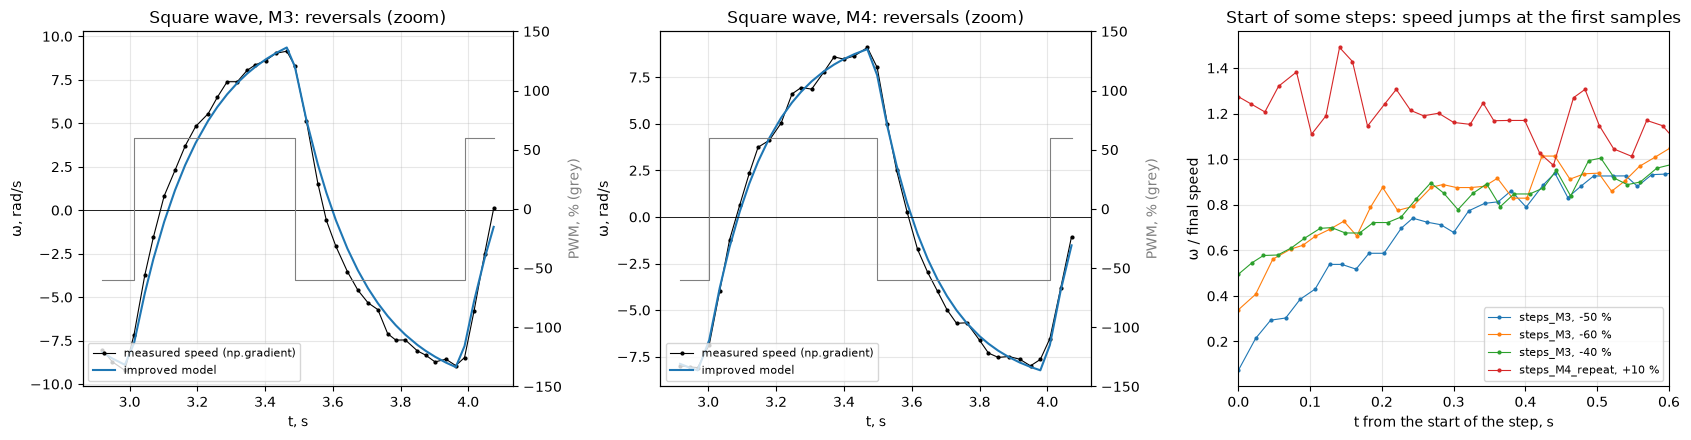

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, m in zip(axs[:2], ('M3', 'M4')):
    t_log, th, w_meas, pwm = meas['square', m]
    w_raw = np.gradient(th, t_log)                                 # measured speed, no smoothing
    w_sim = sim['square', m, 'improved'][:, 0]
    def zero_time(w, k):                                           # first time after sample k when w changes sign
        j = k + np.flatnonzero(np.sign(w[k:]) != np.sign(w[k - 1]))[0]
        return t_log[j - 1] + (t_log[j] - t_log[j - 1]) * w[j - 1] / (w[j - 1] - w[j])
    delays = []
    for k in np.flatnonzero(np.sign(pwm[1:]) * np.sign(pwm[:-1]) < 0) + 1:   # first sample after a reversal
        if t_log[k] < 7.9:
            delays.append(1000 * (zero_time(w_raw, k) - zero_time(w_sim, k)))
    delays = np.array(delays)
    when = 'earlier' if delays.mean() < 0 else 'later'
    print(f'{m}: {len(delays)} reversals; the measured speed crosses zero on average {abs(delays.mean()):.0f} ms {when} '
          f'than the model (standard deviation {delays.std():.0f} ms, range {delays.min():+.0f} … {delays.max():+.0f} ms)')
    zoom = (t_log > 2.9) & (t_log < 4.1)
    ax.plot(t_log[zoom], w_raw[zoom], 'k.-', ms=4, lw=0.8, label='measured speed (np.gradient)')
    ax.plot(t_log[zoom], w_sim[zoom], '-', color='tab:blue', label='improved model')
    ax.axhline(0, color='k', lw=0.6)
    ax2 = ax.twinx(); ax2.step(t_log[zoom], pwm[zoom], where='post', color='grey', lw=0.8); ax2.grid(False)
    ax2.set_ylabel('PWM, % (grey)', color='grey'); ax2.set_ylim(-150, 150)
    ax.set_title(f'Square wave, {m}: reversals (zoom)'); ax.set_xlabel('t, s'); ax.set_ylabel('ω, rad/s')
    ax.legend(fontsize=8, loc='lower left')

ax = axs[2]
for name, lv in (('steps_M3', -50), ('steps_M3', -60), ('steps_M3', -40), ('steps_M4_repeat', 10)):
    s = [x for x in split_levels(*raw[name]) if x['level'] == lv][0]
    late = s['t'] > 1.5
    w_end = np.polyfit(s['t'][late], s['theta'][late], 1)[0]      # final speed (last 0.5 s)
    ax.plot(s['t'], np.gradient(s['theta'], s['t']) / w_end, '.-', ms=4, lw=0.8, label=f'{name}, {lv:+d} %')
ax.set_xlim(0, 0.6); ax.set_xlabel('t from the start of the step, s'); ax.set_ylabel('ω / final speed')
ax.set_title('Start of some steps: speed jumps at the first samples'); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Figure 11.** Left and middle: measured speed (`np.gradient`) and the improved model around reversals of the square wave. Right: speed divided by the final speed at the start of some steps: a normal start (M3 −50 %) and steps that start with a jump.

At the reversals of the square wave I see no flat part and no extra delay. The measured speed passes zero smoothly, on average 18 ms (M3) and 15 ms (M4) earlier than the model. This is about half a sample, so the backlash is smaller than what I can see with ~30 ms sampling. One reason may be that the encoder is on the motor shaft, before the gearbox. Then the encoder does not stop when the gear teeth separate.

I also found another effect. In some steps (M3 −60 %, −40 %, +70 %; repeated M4 +10 %, +40 %) the speed at the first samples is already 40–70 % of the final speed, or even more than 100 %. A normal step (M3 −50 %) starts from zero. I think in these steps the gear teeth had a small gap after the previous coasting. Then the motor first turned almost without load through the gap, and only after that it had to accelerate the wheel. But I am not sure. These are the same levels where $T_m$ in Figure 3 is too small.

### 5.7 Sampling jitter

Program A (steps, 1 % run): Δt mean 20.7 ms, median 20 ms, min 13 ms, max 63 ms, std 3.7 ms, 0.3 % of intervals ≥ 40 ms
Program B (square, chirp): Δt mean 29.5 ms, median 30 ms, min 14 ms, max 51 ms, std 6.4 ms, 6.6 % of intervals ≥ 40 ms


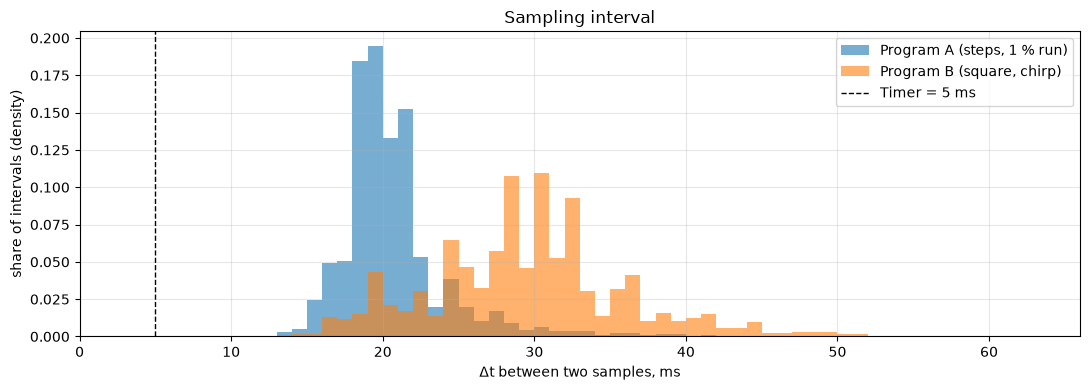

One encoder step (1 deg) in one interval of 20 ms = 0.87 rad/s, of 30 ms = 0.58 rad/s. np.gradient uses two intervals, so its steps are about 0.44 and 0.29 rad/s.


In [19]:
fig, ax = plt.subplots(figsize=(11, 4))
groups = {'Program A (steps, 1 % run)': ['steps_M3', 'steps_M4', 'steps_M4_repeat', 'deadzone_M3', 'deadzone_M4'],
          'Program B (square, chirp)': ['square_M3', 'square_M4', 'chirp_M3', 'chirp_M4']}
for label, names in groups.items():
    dt = np.concatenate([1000 * np.diff(raw[n][1]) for n in names])
    ax.hist(dt, bins=np.arange(10, 66, 1), alpha=0.6, density=True, label=label)
    print(f'{label}: Δt mean {dt.mean():.1f} ms, median {np.median(dt):.0f} ms, min {dt.min():.0f} ms, '
          f'max {dt.max():.0f} ms, std {dt.std():.1f} ms, {100 * np.mean(dt >= 40):.1f} % of intervals ≥ 40 ms')
ax.axvline(5, color='k', ls='--', lw=1, label='Timer = 5 ms')
ax.set_xlabel('Δt between two samples, ms'); ax.set_ylabel('share of intervals (density)'); ax.set_xlim(0, 66)
ax.set_title('Sampling interval'); ax.legend()
plt.tight_layout()
plt.show()
print(f'One encoder step (1 deg) in one interval of 20 ms = {np.deg2rad(1) / 0.020:.2f} rad/s, '
      f'of 30 ms = {np.deg2rad(1) / 0.030:.2f} rad/s. np.gradient uses two intervals, so its steps are about '
      f'{np.deg2rad(1) / 0.040:.2f} and {np.deg2rad(1) / 0.060:.2f} rad/s.')

**Figure 12.** Histogram of the interval between two samples for Program A and Program B. The dashed line is the 5 ms timer.

The timer is 5 ms, but the real interval is about 20 ms in Program A (mean 20.7 ms, min 13 ms, max 63 ms) and about 30 ms in Program B (mean 29.5 ms, min 14 ms, max 51 ms). Writing a line to the file takes most of the time. Program B also computes the signal formula and goes through up to three If blocks in every cycle. Effects:
- I must always use the real time stamps. With the assumed 5 ms, all speeds would be 4–6 times too high.
- One encoder step (1°) in one interval is 0.87 rad/s at 20 ms and 0.58 rad/s at 30 ms, so the speed from neighbour samples is noisy (5.9).
- $T_m$ at 100 % (0.03–0.04 s) is only 1.5–2 samples long, so I cannot measure it well.
- At 5 Hz the chirp has only 6–7 PWM values per period.

The course README suggests to keep the samples in memory and write the file after the run. This would make the interval shorter and more regular.

### 5.8 Battery sag

In [20]:
print(f'Battery voltage: {U_BEFORE:.1f} V before, {U_AFTER:.1f} V after, change = {U_AFTER - U_BEFORE:+.1f} V')
print(f'My reading has one decimal (±0.05 V), so U_battery adds only ±{100 * 0.05 / U_BAT:.1f} % uncertainty to k_e.')
r1, r2 = tab['steps_M4'], tab['steps_M4_repeat']
diff_w = 100 * (r2.w_ss / r1.w_ss - 1)
diff_T = 100 * (r2.T_m / r1.T_m - 1)
lin = r1.PWM.abs() >= LINEAR_FROM
print(f'M4 repeat vs run 1, |PWM| ≥ {LINEAR_FROM} %: ω_ss differs by {diff_w[lin].mean():+.2f} % on average '
      f'(from {diff_w[lin].min():+.1f} to {diff_w[lin].max():+.1f} %)')
ok = (r1.T_m > 0.002) & (r2.T_m > 0.002)                  # leave out the failed fit (T_m at the lower limit)
print(f'M4 repeat vs run 1, all levels: mean |difference| of ω_ss = {diff_w.abs().mean():.1f} %; '
      f'|difference| of T_m without the failed fit: median {diff_T[ok].abs().median():.0f} %, '
      f'largest {diff_T[ok].abs().max():.0f} %')
display(pd.DataFrame({'PWM, %': r1.PWM, 'ω_ss run 1': r1.w_ss, 'ω_ss repeat': r2.w_ss, 'difference, %': diff_w,
                      'T_m run 1': r1.T_m, 'T_m repeat': r2.T_m}).T.round(3))

Battery voltage: 11.2 V before, 11.2 V after, change = +0.0 V
My reading has one decimal (±0.05 V), so U_battery adds only ±0.4 % uncertainty to k_e.
M4 repeat vs run 1, |PWM| ≥ 30 %: ω_ss differs by +0.50 % on average (from -0.4 to +1.3 %)
M4 repeat vs run 1, all levels: mean |difference| of ω_ss = 1.7 %; |difference| of T_m without the failed fit: median 12 %, largest 62 %


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
"PWM, %",-100.000,-90.000,-80.000,-70.000,-60.000,-50.000,-40.000,-30.000,-20.000,-10.000,10.000,20.000,30.000,40.000,50.000,60.000,70.000,80.000,90.000,100.000
ω_ss run 1,-13.925,-12.558,-11.471,-10.273,-9.198,-8.266,-7.482,-6.135,-4.819,-3.361,3.703,5.519,6.839,8.355,9.174,10.052,11.133,12.526,13.760,15.236
ω_ss repeat,-13.924,-12.624,-11.538,-10.318,-9.204,-8.318,-7.563,-6.159,-5.023,-3.155,4.223,5.499,6.916,8.318,9.278,10.185,11.230,12.546,13.776,15.230
"difference, %",-0.008,0.528,0.589,0.436,0.064,0.626,1.085,0.382,4.231,-6.126,14.049,-0.356,1.128,-0.435,1.138,1.325,0.871,0.163,0.122,-0.043
T_m run 1,0.040,0.064,0.102,0.134,0.154,0.176,0.186,0.237,0.244,0.354,0.256,0.302,0.245,0.207,0.190,0.154,0.094,0.102,0.081,0.044
T_m repeat,0.032,0.071,0.100,0.126,0.103,0.173,0.213,0.221,0.303,0.253,0.001,0.264,0.240,0.079,0.207,0.170,0.149,0.086,0.066,0.045


I noted the battery voltage before and after every series. It was 11.2 V before and 11.2 V after each time, and it stayed the same during the whole lab. So I see no battery sag: if there was a drop, it was smaller than 0.1 V, the resolution of my reading (less than 1 %). My data agree with this. The repeated M4 run, which I made after the first one, gives speeds that differ by only +0.5 % on average above 30 % (−0.4 … +1.3 %). If the voltage had dropped, all speeds of the second run would be lower. Because my reading has one decimal, $U_{battery}$ is known to about ±0.05 V, which changes $k_e$ by only ±0.4 %.

### 5.9 Encoder quantisation and differentiation noise

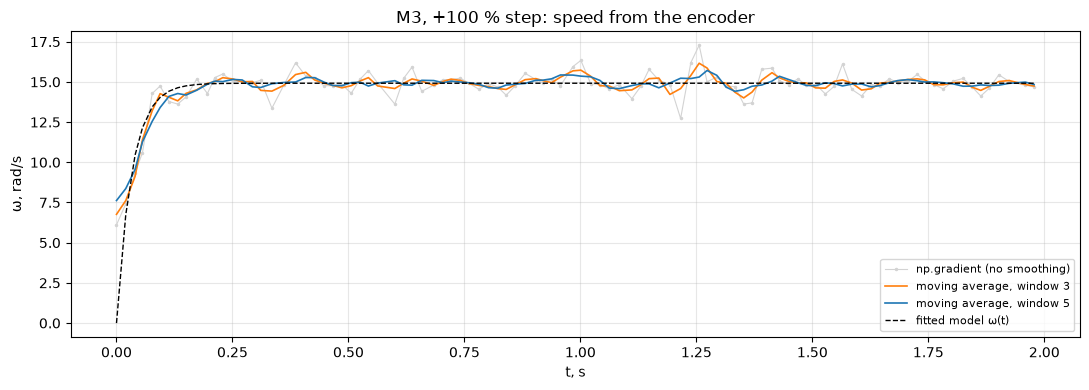

steps_M3  50 %: mean 10.28 rad/s; std, window 1: 0.43 rad/s, window 3: 0.26 rad/s, window 5: 0.19 rad/s
steps_M3 100 %: mean 14.93 rad/s; std, window 1: 0.72 rad/s, window 3: 0.40 rad/s, window 5: 0.25 rad/s
steps_M4  50 %: mean 9.26 rad/s; std, window 1: 0.61 rad/s, window 3: 0.35 rad/s, window 5: 0.28 rad/s
steps_M4 100 %: mean 15.37 rad/s; std, window 1: 0.75 rad/s, window 3: 0.36 rad/s, window 5: 0.25 rad/s


In [21]:
s = [x for x in segs['steps_M3'] if x['level'] == 100][0]
w_raw = np.gradient(s['theta'], s['t'])
steady = s['t'] > 1.0
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(s['t'], w_raw, '.-', color='lightgrey', ms=3, lw=0.8, label='np.gradient (no smoothing)')
for win, c in ((3, 'tab:orange'), (5, 'tab:blue')):
    ax.plot(s['t'], smooth(w_raw, win), '-', color=c, lw=1.2, label=f'moving average, window {win}')
ax.plot(s['t'], s['w_ss'] * (1 - np.exp(-s['t'] / s['T_m'])), 'k--', lw=1, label='fitted model ω(t)')
ax.set_xlabel('t, s'); ax.set_ylabel('ω, rad/s'); ax.set_title('M3, +100 % step: speed from the encoder')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for name in ('steps_M3', 'steps_M4'):
    for lv in (50, 100):
        s = [x for x in segs[name] if x['level'] == lv][0]
        w_raw = np.gradient(s['theta'], s['t']); steady = s['t'] > 1.0
        out = [f'{name} {lv:3d} %: mean {w_raw[steady].mean():.2f} rad/s; std']
        for win in (1, 3, 5):
            out.append(f'window {win}: {smooth(w_raw, win)[steady].std():.2f} rad/s')
        print(', '.join(out))

**Figure 13.** Speed of M3 at +100 % from `np.gradient` without smoothing (grey) and with moving averages of 3 and 5 samples, compared with the fitted model $\omega(t)$.

The encoder resolution is 1° = 0.0175 rad. One encoder step in one 20 ms interval means 0.87 rad/s. `np.gradient` uses the samples before and after (about 40 ms), so its speed changes in steps of about 0.44 rad/s. In the steady part (t > 1 s) the speed from `np.gradient` has a standard deviation of 0.4–0.75 rad/s (4–7 % of the speed). A moving average of 3 samples reduces it to 0.26–0.40 rad/s, and of 5 samples to 0.19–0.28 rad/s. But a longer window also makes fast changes slower: at the start of the step the smoothed curves lag behind the model. I used a window of 3 for the complex signals, because at 5 Hz one period has only 6–7 samples.

### 5.10 Motor-to-motor spread

In [22]:
rows = []
for d in ('fwd', 'bwd'):
    a, b = par['M3', d], par['M4', d]
    for key, label in (('slope', 'slope, rad/s per %'), ('b', 'offset b, rad/s'), ('k_e', 'k_e, V·s/rad'),
                       ('T_m', 'mean T_m, s'), ('dead zone, %', 'dead zone, %')):
        rows.append([d, label, a[key], b[key], pct(a[key], b[key]) if key != 'dead zone, %' else np.nan])
w3 = dict(zip(tab['steps_M3'].PWM, tab['steps_M3'].w_ss)); w4 = dict(zip(tab['steps_M4'].PWM, tab['steps_M4'].w_ss))
for lv in (30, 60, 100, -30, -60, -100):
    rows.append(['fwd' if lv > 0 else 'bwd', f'ω_ss at {lv:+d} %, rad/s', w3[lv], w4[lv], pct(w3[lv], w4[lv])])
spread = pd.DataFrame(rows, columns=['direction', 'quantity', 'M3 (right)', 'M4 (left)', 'M3 − M4, %'])
display(spread.round(3))

,direction,quantity,M3 (right),M4 (left),"M3 − M4, %"
0,fwd,"slope, rad/s per %",0.095,0.115,-19.832
1,fwd,"offset b, rad/s",5.490,3.383,47.503
2,fwd,"k_e, V·s/rad",1.184,0.970,19.832
3,fwd,"mean T_m, s",0.197,0.168,16.242
4,fwd,"dead zone, %",0.000,0.000,NaN
5,bwd,"slope, rad/s per %",0.094,0.108,-13.288
6,bwd,"offset b, rad/s",-4.998,-2.903,53.020
7,bwd,"k_e, V·s/rad",1.186,1.038,13.288
8,bwd,"mean T_m, s",0.186,0.169,9.637
9,bwd,"dead zone, %",0.000,4.000,NaN


The right motor (M3) and the left motor (M4) are different. At 30–60 % PWM the right wheel is 10–20 % faster. At 100 % both wheels have almost the same speed (−2 … +3 %). The reason is that M4 has a steeper line (0.115 / 0.108 vs 0.095 / 0.094 rad/s per %) but a smaller offset (3.4 / 2.9 vs 5.5 / 5.0 rad/s). M3 has a 10–16 % longer mean $T_m$, and only M4 has a backward dead zone.

So if I give the same PWM to both wheels, the robot will not drive straight. At 60 % the right wheel is about 10 % faster, so the robot will turn to the left (if positive PWM drives both wheels forward). Each wheel needs its own parameters.

### 5.11 Other artifacts I found

In [23]:
for m in ('M3', 'M4'):
    theta, t, pwm = raw['square_' + m]
    ts = t - t[0]
    zero = np.flatnonzero((pwm == 0) & (ts < 7.95))                 # PWM = 0 inside the square wave
    print(f'square {m}: PWM = 0 inside the signal at t = {np.round(ts[zero], 3)} s')
s = [x for x in split_levels(*raw['deadzone_M3']) if x['level'] == 1][0]
w = np.gradient(s['theta'], s['t'])
print(f"M3 +1 % (dead-zone run): mean speed in the first 0.1 s = {np.mean(w[s['t'] < 0.1]):.2f} rad/s, "
      f"speed in the last 0.5 s = {fine['M3'].w_end[fine['M3'].PWM == 1].iloc[0]:.2f} rad/s")

square M3: PWM = 0 inside the signal at t = [7.479] s
square M4: PWM = 0 inside the signal at t = [7.483] s
M3 +1 % (dead-zone run): mean speed in the first 0.1 s = 4.97 rad/s, speed in the last 0.5 s = 1.07 rad/s


- $T_m$ depends on PWM (Figure 3): about 10 times between ±10 % and ±100 % (Section 4.3).
- Speed steps at low PWM (Figure 2, zoom): 2–5 % and 6–9 % give nearly the same speed.
- Strange start at +1 % (M3, dead-zone run): the wheel started fast (about 5 rad/s in the first 0.1 s) and then slowed down to about 1 rad/s (Figure 8, right). This came right after the −1 % level. I cannot explain it with my data. I would need to repeat this level.
- A zero sample inside my square wave: `sgn(0.5 - fr)` is 0 when `fr` is exactly 0.5. This happened once in each run (t ≈ 7.48 s): one sample with PWM = 0. With the condition `fr < 0.5` this would not happen.
- Coarse input at high frequency: at 5 Hz the chirp has only 6–7 PWM values per period (Figure 5), so the real input is not a smooth sine.

### 5.12 Model assumptions tested with my data

| Assumption | What my data show | Holds? |
|---|---|---|
| No inductance | I cannot see the electrical time constant with 20–30 ms sampling. At ±100 % the speed reaches 63 % in 0.03–0.04 s, and the first-order curve fits well (Figure 1). | OK at my sampling rate |
| Linear viscous friction | After power-off the speed falls along a straight line (constant deceleration 14–17 rad/s², Figure 10). This is dry friction. M4 backward has a dead zone. | No |
| Constant load | Wheels lifted, nothing changed during a run. For \|PWM\| ≥ 30 % the repeated M4 run gives the same $\omega_{ss}$ within about 1 %. | Yes |
| Constant battery voltage within a run | 11.2 V before and 11.2 V after every series. The repeated M4 run gives speeds within +0.5 % of the first run. | Yes |
| $T_m$ and $k_e$ are constants | $T_m$ changes from 0.03–0.04 s (±100 %) to 0.26–0.45 s (±10 %). The speed line has an offset $b$ = 2.9–5.5 rad/s, so $U/\omega_{ss}$ is not constant. | No |

## 6. Report

### 6.1 Estimated values
- Dead zone: the largest |PWM| where the wheel did not move in the 1 % run.
- Slope and $k_e$: from the straight line over |PWM| ≥ 30 %.
- Mean $T_m$: mean over the 10 levels of that direction ± standard deviation across the levels. This is the spread over PWM, not the error of one fit.
- $U_{battery}$ = 11.2 V: my measured value (the same before and after).

In [24]:
for m in ('M3', 'M4'):
    rows = []
    for d, name in (('fwd', 'Forward'), ('bwd', 'Backward')):
        p = par[m, d]
        dz = p['dead zone, %']
        rows.append([name, f"{dz:.0f} (moves from {dz + 1:.0f} %)", f"{p['slope']:.4f}", f"{p['k_e']:.3f}",
                     f"{p['T_m']:.3f} ± {p['T_m_std']:.3f}", f'{U_BAT:.1f}'])
    print(f'Motor {m} ({WHEEL[m]})')
    display(pd.DataFrame(rows, columns=['Direction', 'Dead zone, % PWM', 'Slope, rad/s per % PWM',
                                        'k_e, V·s/rad', 'Mean T_m, s', 'U_battery, V']).set_index('Direction'))
extra = []
for m in ('M3', 'M4'):
    for d in ('fwd', 'bwd'):
        p = par[m, d]
        w60 = abs(np.interp(60 if d == 'fwd' else -60, *CURVE[m]))
        extra.append([m, d, p['b'], 0.6 * U_BAT / w60, p['T_m_min'], p['T_m_max'], T_COAST[m]])
print('Extra values that my model needs')
display(pd.DataFrame(extra, columns=['motor', 'direction', 'offset b of the line, rad/s', 'U/ω_ss at ±60 %, V·s/rad',
                                     'T_m min, s', 'T_m max, s', 'T_coast, s']).round(3))

Motor M3 (right wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,
Forward,0 (moves from 1 %),0.0946,1.184,0.197 ± 0.118,11.2
Backward,0 (moves from 1 %),0.0944,1.186,0.186 ± 0.133,11.2


Motor M4 (left wheel)


,"Dead zone, % PWM","Slope, rad/s per % PWM","k_e, V·s/rad","Mean T_m, s","U_battery, V"
Direction,,,,,
Forward,0 (moves from 1 %),0.1154,0.970,0.168 ± 0.086,11.2
Backward,4 (moves from 5 %),0.1079,1.038,0.169 ± 0.093,11.2


Extra values that my model needs


,motor,direction,"offset b of the line, rad/s","U/ω_ss at ±60 %, V·s/rad","T_m min, s","T_m max, s","T_coast, s"
0,M3,fwd,5.490,0.603,0.033,0.356,0.358
1,M3,bwd,-4.998,0.634,0.033,0.453,0.358
2,M4,fwd,3.383,0.669,0.044,0.302,0.260
3,M4,bwd,-2.903,0.731,0.040,0.354,0.260


The second table has the values that my improved model needs: the offset $b$ of the line, the "effective" $k_e = U/\omega_{ss}$ at ±60 %, the range of $T_m$ and the coasting time constant.

### 6.2 Required plots

| Plot | Where |
|---|---|
| Step responses $\theta(t)$ with the fitted model | Figure 1 (Section 4.2) |
| Speed from PWM, both motors, linear fits, dead zone | Figure 2 (4.3) |
| $T_m$ from PWM with error bars | Figure 3 (4.3) |
| Complex signal: measured vs simulated angle and speed, with the input PWM | Figures 4 and 5 (4.4) |
| Complex signal: error over time | Figures 4 and 5, bottom row |
| Chirp: amplitude ratio against frequency | Figure 6 (4.4) |
| Zero-drift record | Figure 7 (5.2) |
| Other artifacts | Figures 8–13 (5.3–5.9) |

### 6.3 Analysis

**1. How well does the first-order model with constant $T_m$ and $k_e$ describe the motor?**

The course model with constant $T_m$ and $k_e$ from the slope does not describe my motors well. The angle fit is −46 % (M3) and 33 % (M4) on the square wave, and −158 % and −72 % on the chirp. The main reason is that my speed line does not go through zero. It has an offset of 3–5.5 rad/s, so at 60 % PWM $U/k_e$ gives only about half (M3) to 70 % (M4) of the real speed. Adding the dead zone changes almost nothing, because my dead zone is very small (0 % in three directions, 4 % for M4 backward). When I use my measured speed curve (with the offset and the dead zone) and let the wheel coast when PWM = 0, the model follows the speed very well. The speed fit is 89 % on the square wave for both motors and 77 % / 75 % on the chirp. The angle fit is 75 % / 29 % on the square and 64 % / 31 % on the chirp (M3 / M4).

The angle error is largest in two places. First, in the first second of the chirp (up to 1 rad): there the PWM is small, and the real motor is slower than the model, because $T_m$ at low PWM is much longer than the mean value I use. Second, a slow drift during the whole run. For M3 the drift is small (about 1 % of the total travel). For M4 the model turns backward 7 % (square) and 16 % (chirp) less than the real wheel. This is more than the difference between my two M4 runs (about 1 %), so the M4 backward parameters from the step tests do not describe fast reversals well.

**2. Forward vs backward: are the two directions the same motor? One set of parameters or two?**

For M3 the two directions are almost the same. The slope and $k_e$ differ by only 0.2 %, but the offset is 9 % bigger forward, so $\omega_{ss}$ is 3.5–5 % higher forward at the same |PWM|. For M4 the difference is bigger: slope +7 %, offset +15 %, $\omega_{ss}$ about +9 % forward, and only the backward direction has a dead zone (4 %). $T_m$ is the same within 6 % in both directions, which is small compared with its change over PWM. Both motors turn faster forward, so the angle after the full step series is not zero (+732° for M3, +1235° for M4). For M3 one set of parameters would give an error of 5 % or less. For M4 one set would give about 9 % speed error in one direction, and the square wave and the chirp show that M4 backward is even harder to predict. So I think the controller should use two sets (forward and backward) for each wheel, including the offset $b$. This is easy to do and removes this error.

**3. Which artifacts did I find, how large are they, and which matter for odometry next week?**

What I found:
- the offset of the speed line (2.9–5.5 rad/s) and steps in the speed at low PWM
- $T_m$ changes about 10 times with PWM
- long coasting after power-off: 0.4–7 rad, up to about 1 s, dry friction 14–17 rad/s²
- forward/backward asymmetry of 3.5–10 %
- motor-to-motor spread of 10–20 % at 30–60 % PWM
- a small dead zone (0–4 %)
- a sampling interval of 20–30 ms instead of 5 ms (13–63 ms)
- differentiation noise of 0.4–0.75 rad/s without smoothing
- possible backlash at the start of some steps
- no zero drift, and no battery sag (11.2 V before and after)

What matters for odometry (I will integrate the encoder angles):
- Use the real time stamps, never 5 ms.
- Encoder quantisation: compute the pose from angle differences, and do not trust the speed from two neighbour samples.
- Coasting: the robot keeps moving for up to about 1 s after the motor is switched off. I measured this with lifted wheels; on the floor it will be shorter. So odometry must keep running after the stop command.
- Backlash: if the encoder is on the motor shaft, small movements at reversals can be counted although the wheel does not move. I could not see it in the square wave, so it is small.

Zero drift is not a problem: the encoder does not change when the motor is off. The motor-to-motor spread and the asymmetry do not change the odometry itself. But they explain why the robot will not drive straight with equal PWM, so the controller must correct it.

**4. Which complex signal did I choose and what did it show that the step series did not?**

I recorded two signals: a square wave (±60 %, P = 1 s) and a chirp (60 %, 0.2 → 5 Hz in 8 s). The square wave showed the motor during fast reversals from +ω to −ω. This never happens in the step series, where every step starts from rest. The speed during the reversals is reproduced well (speed fit 89 %), and there is no flat part at the reversals, so the backlash is below my time resolution. It also showed that M4 turns backward more in fast reversals than my step tests predict, and this makes the angle drift. The chirp showed the frequency response: the speed amplitude falls from about 1.2 rad/s per volt at 0.7 Hz to about 0.2 at 4.8 Hz. Fitting the first-order formula gives $T_m$ ≈ 0.18 s for both motors, which agrees with the mean $T_m$ of the steps. It also showed that $k_e$ from the slope underestimates the gain 1.6–1.9 times, and that at low PWM (the first second) the motor is slower than the model. The step series could not show this, because every step is one constant input from rest.

### 6.4 What I would do better next time
- Keep the samples in memory and write the file after the run, to get a shorter and more regular sampling interval.
- Use a longer coasting time (1.5 s or more), so that the wheel always stops before the next level.
- Repeat the strange levels (for example M3 +1 %) and make one run on the floor, to see the effect of the load.